By: 
Saketh Reddy Chandupatla - X00231080

## Plant Disease Detection Using Transfer Learning and Explainable AI

## Section 1: Introduction

Productivity in agriculture is very dependent on the early detection of the plant diseases and its treatment. In many parts of the world maize(corn) represents a staple crop and is a vital source of food security. However many infections like fungal,viral and bacterial are affectiing maize leaves which can significantly reduce the crop yield and quality. With the help of recent advancements in computer vision and machine learning algorithms, it provides a promising start to automating and supporting farmers with rapid diagnostic tools.

This project uses the publicly available PlantVillage dataset (sourced from https://www.kaggle.com/datasets/emmarex/plantdisease) which has over 50,000 labelled images of healthy and diseased leaves from a different variety of plant species. While the dataset includes numerous crops like potato, tomato and grape, this project focuses mainly on the subset containing images of maize leaves covering several disease cateogaries like Common Rust, Cercospora Leaf Spot, and Northern Leaf Blight. The dataset consists of RGB images which are captured under controlled conditions with uniform backgrounds, which providea a clean and structured foundation for this model development.

The main reason for choosing this dataset lies in its rich and labelled image data with its high relevance to real-world agriculture challenge. Working while focusing on maize specifically allows us to narrow the scope of the project while addressing significant global importance. The objective of this project is to build and evaluate both a high-performance deep learning model (EfficientNetB3) and an interpretable glassbox model (Decision Tree). With this we aim to compare predictive accuracy with transparency of decision making which provides insights to tradeoffs between model performance and explainability in a critical domain application.

| Folder Name (Label)                                  | Class Type |
| ---------------------------------------------------- | ---------- |
| `Corn_(maize)___healthy`                             | Healthy    |
| `Corn_(maize)___Common_rust`                         | Diseased   |
| `Corn_(maize)___Northern_Leaf_Blight`                | Diseased   |
| `Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot` | Diseased   |

Table shows how each image is seperated in the dataset. Each image is stored in a folder corresponding to its plant type and a disease label(healthy when its healthy) attached to it.

## Section 2: Opening the dataset, Brief data exploration and data pre-processing

The maize subset of the PlantVillage dataset was loaded to begin exploratory analysis and preprocessing. This subset has 4 classes: healthy leaves and three diseased categories that are Common Rust, Northern Leaf Blight, Cercospora Leaf spot. Understanding the structure of dataset, class distribution and image characteristics is important for identifying any potential biases and also preparing the data for training robust models. Proper preprocessing makes sure that the models learn features that generalize well across variations in lighting, orientation and leaf appearance.

In [ ]:
!pip install split-folders


Copying files: 1652 files [24:01,  1.15 files/s]


In [ ]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from PIL import Image


In [ ]:
import splitfolders

In [ ]:
raw_data_dir = "/content/drive/MyDrive/CA3"
output_split_dir = "/content/drive/MyDrive/CA3_split1"

# This will create train/, val/, and test/ subfolders
splitfolders.ratio(raw_data_dir,
                   output=output_split_dir,
                   seed=42,
                   ratio=(.7, .2, .1),
                   move=False)  # move=False will copy instead of moving


Copying files: 4570 files [01:09, 65.57 files/s] 


The dataset was split into training 70%, validation 20% and test 10% sets. This makes sure that the model has sufficient training data while also retaining samples for unbiased evaluation. The 10% test is specifically reserved as to evaluate data on unseen data so that it can provide unbiased measure of its generalization performance.

In [ ]:
output_split_dir = "/content/drive/MyDrive/CA3_split1"


In [ ]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory

In [ ]:

# 1.2 Define dataset paths
train_dir = os.path.join(output_split_dir, "train")
val_dir = os.path.join(output_split_dir, "val")
test_dir = os.path.join(output_split_dir, "test")

def remove_ipynb_checkpoints(directory):
    for root, dirs, files in os.walk(directory, topdown=True):
        if '.ipynb_checkpoints' in dirs:
            checkpoints_dir = os.path.join(root, '.ipynb_checkpoints')
            print(f"Removing {checkpoints_dir}")
            shutil.rmtree(checkpoints_dir)

remove_ipynb_checkpoints(train_dir)
remove_ipynb_checkpoints(val_dir)
remove_ipynb_checkpoints(test_dir)


In [ ]:


# 1.3 Load datasets with Keras image_dataset_from_directory
# Define image size and batch size
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

# Load train dataset with augmentation
train_dataset = image_dataset_from_directory(
    train_dir,
    label_mode='int',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

# Load val and test datasets without augmentation
val_dataset = image_dataset_from_directory(
    val_dir,
    label_mode='int',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_dataset = image_dataset_from_directory(
    test_dir,
    label_mode='int',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 3198 files belonging to 4 classes.
Found 913 files belonging to 4 classes.
Found 459 files belonging to 4 classes.


- This output confirms that the split preserved all 4 classes.
- The training set contains the majority of images(3198), ensures that there are enough samples for the model to learn robust features.
- Validation and test are smaller but sufficient to measure model generalization.

In [ ]:

# 1.4 Define augmentation as a tf.keras.Sequential model (for train only)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
])


In [ ]:


# 1.5 Normalize function (same normalization as your PyTorch)
def normalize_img(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    mean = tf.constant([0.485, 0.456, 0.406])
    std = tf.constant([0.229, 0.224, 0.225])
    image = (image - mean) / std
    return image, label



# Save before any mapping
class_names = train_dataset.class_names
print("Class names:", class_names)
# Apply augmentation and normalization to train dataset
train_dataset = train_dataset.map(lambda x, y: (data_augmentation(x, training=True), y))
train_dataset = train_dataset.map(normalize_img)


# Normalize val and test datasets
val_dataset = val_dataset.map(normalize_img)
test_dataset = test_dataset.map(normalize_img)

Class names: ['Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot_', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy']


- Class names are extracted from the folder namess and will also serve as the labels during training and evaluation.
- Data augumentation introduces a variability in the orientation and flipping to prevent overfitting and improve generalization.
- Normalization centers pixel values using ImageNet statistics which prepares images for transfer learning with EfficientNet.

In [ ]:
y_test_cnn = np.concatenate([labels.numpy() for _, labels in test_dataset], axis=0)


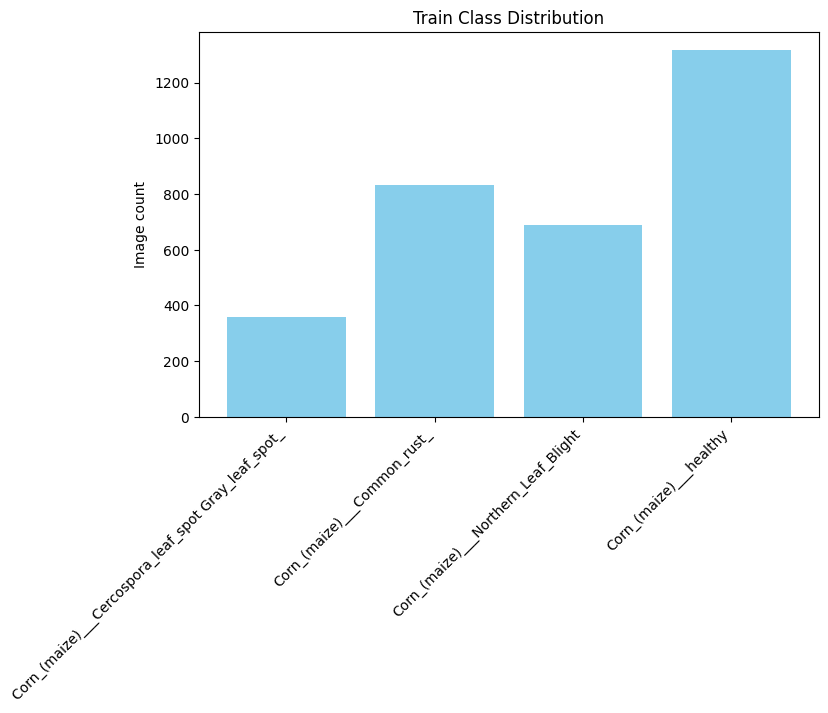

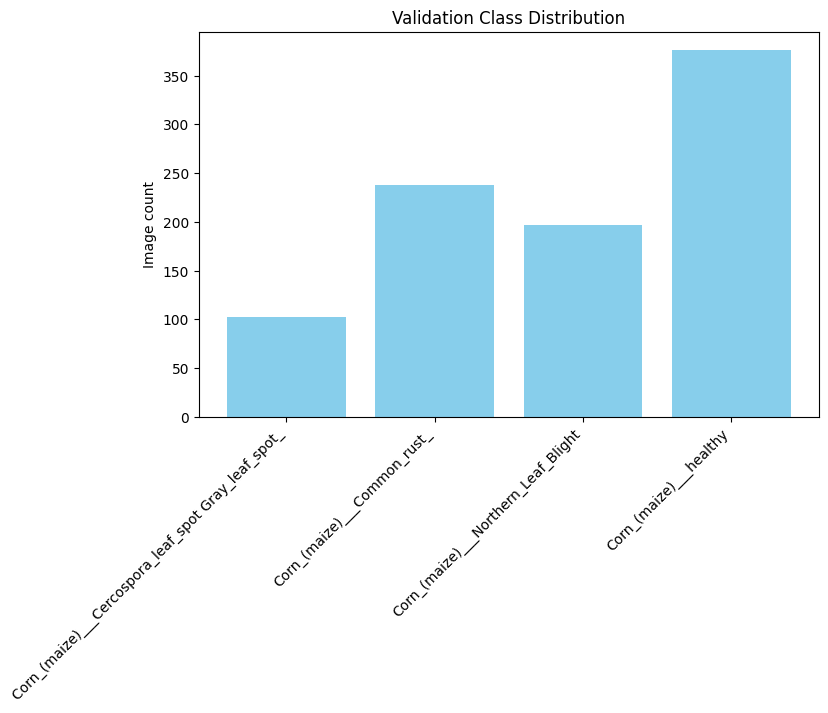

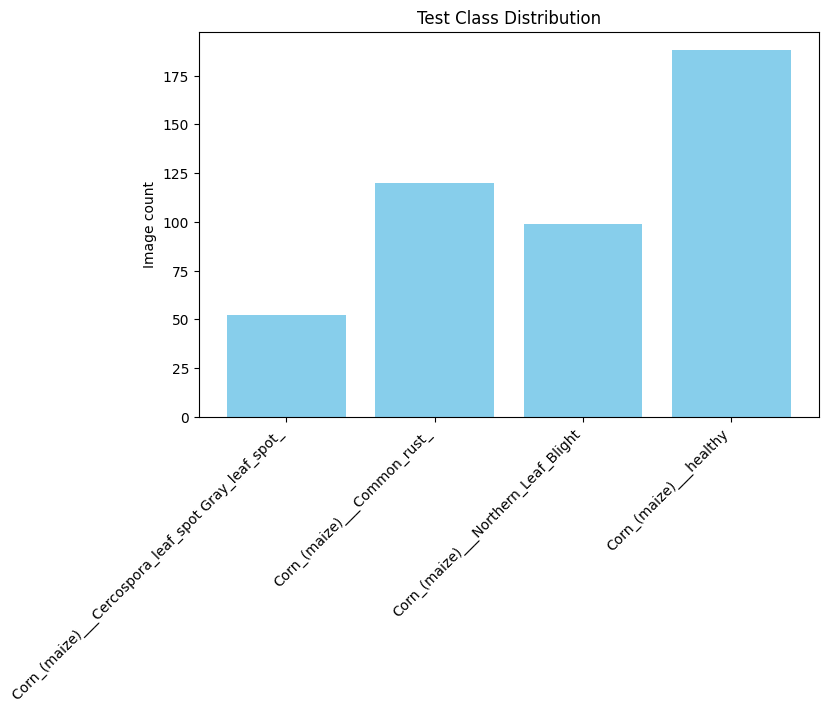

In [ ]:

# 1.6 Class distribution visualization
def plot_class_distribution_from_directory(directory, title):
    class_names = sorted(os.listdir(directory))
    counts = []
    for class_name in class_names:
        class_dir = os.path.join(directory, class_name)
        count = len(os.listdir(class_dir))
        counts.append(count)

    plt.figure(figsize=(8,5))
    plt.bar(class_names, counts, color='skyblue')
    plt.title(f"{title} Class Distribution")
    plt.xticks(rotation=45, ha='right')
    plt.ylabel("Image count")
    plt.show()

plot_class_distribution_from_directory(train_dir, "Train")
plot_class_distribution_from_directory(val_dir, "Validation")
plot_class_distribution_from_directory(test_dir, "Test")

- Training Set: Healthy leaves have most images (approx 1,200 images), while Cercospora Leaf Spot has fewer samples (approx 350).
- Validation Set: Healthy (approx 350), Cercospora (approx 100).
- Test Set: Healthy (approx 190), Cercospora (approx 50).

The bar charts show a slight class imbalance, but the dataset still provides a strong and representative set of images for all classes

Average RGB values (0-1 scale): [0.43959706 0.49446283 0.37999211]


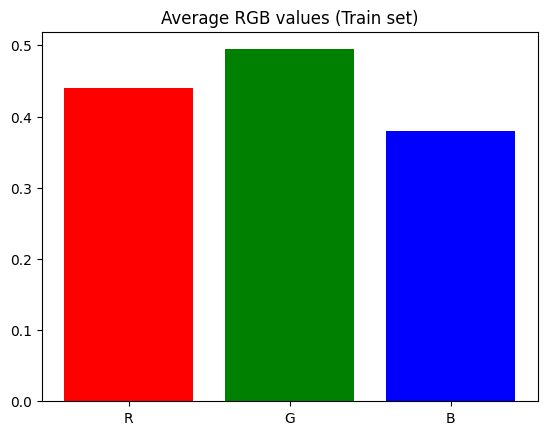

In [ ]:



# 1.7 Compute average RGB values on unnormalized images
def compute_avg_rgb_from_directory(directory, img_size=IMG_SIZE):
    total_sum = np.zeros(3)
    total_pixels = 0
    for class_name in sorted(os.listdir(directory)):
        class_dir = os.path.join(directory, class_name)
        for img_file in os.listdir(class_dir):
            img_path = os.path.join(class_dir, img_file)
            img = tf.keras.preprocessing.image.load_img(img_path, target_size=img_size)
            img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0
            total_sum += img_array.sum(axis=(0,1))
            total_pixels += img_array.shape[0] * img_array.shape[1]
    avg_rgb = total_sum / total_pixels
    return avg_rgb

avg_rgb_values = compute_avg_rgb_from_directory(train_dir)
print("Average RGB values (0-1 scale):", avg_rgb_values)

plt.bar(['R', 'G', 'B'], avg_rgb_values, color=['red', 'green', 'blue'])
plt.title("Average RGB values (Train set)")
plt.show()


- The green channel is the higgest, showcasing the predominance of leaf surfaces in the images.
- The red and blue is lower as its consistent with the natural maize leaf coloration.
- This info is useful for normalization and for understanding the main color distribution in the dataset.

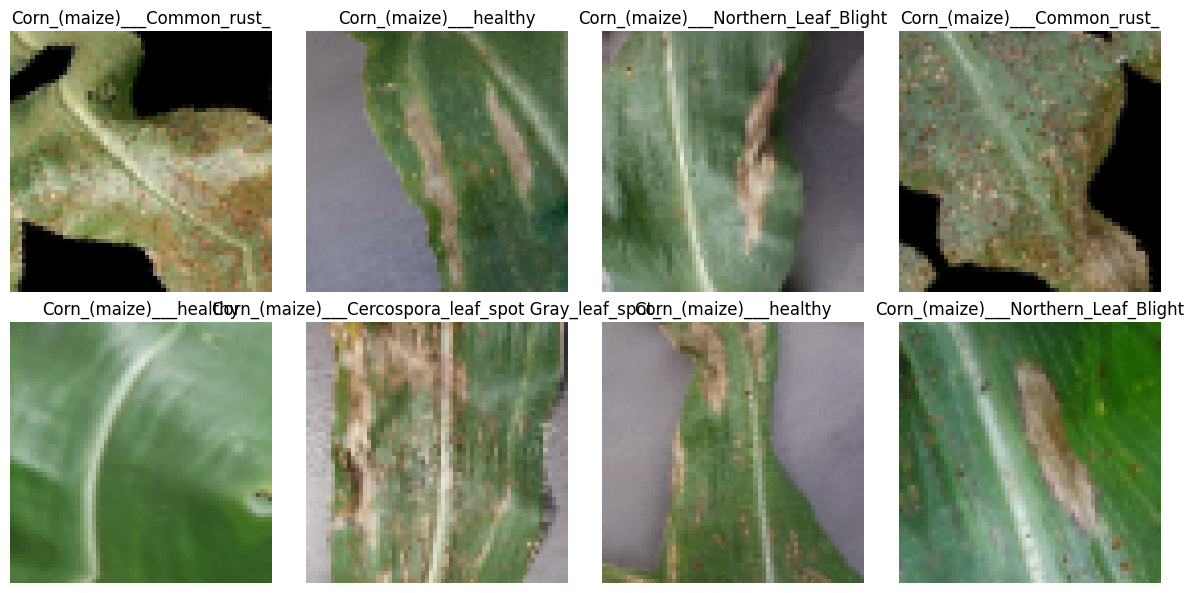

In [ ]:

# 1.8 Visualize sample images from train dataset (unnormalized for display)
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
for images, labels in train_dataset.take(1):
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        img = images[i].numpy()
        # Unnormalize for visualization
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = (img * std) + mean
        img = np.clip(img, 0, 1)
        plt.imshow(img)
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()


- The grid shows a mix of healthy and diseased maize leaves.
- Diseased leaves display characteristic injuries (spots, blights, discolorations) that models must detect
- Health leaves appear smooth and green.

In summary, the dataset was successfully explored, preprocessed, and augmented. The datasets prepared here form the foundation for developing and evaluating our models, which is the focus of Section 3.

## Section 3 :  Model development

**Blackbox Model 1 : Baseline CNN**

Here we establish a Baseline CNN model from scratch, as a performance floor and then use it to inform design choices before moving to transfer learning (EfficientNetB3). Here we run the baseline model and perform systematic tuning and finalize the selected baseline.

Architecture: Sequential CNN with two conv blocks.

- Conv2D(32, 3×3, relu, same) → MaxPool(2×2)
- Conv2D(64, 3×3, relu, same) → MaxPool(2×2)
- Flatten → Dense(64, relu) → Dropout(0.5) → Dense(C, softmax)
- Compilation: optimizer=Adam, loss=sparse_categorical_crossentropy, metrics=[accuracy].
- Training: 20 epochs with EarlyStopping on val_loss (patience=10).


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
100/100 - 21s - 208ms/step - accuracy: 0.6313 - loss: 0.8439 - val_accuracy: 0.7295 - val_loss: 0.5333
Epoch 2/20
100/100 - 15s - 150ms/step - accuracy: 0.6876 - loss: 0.6098 - val_accuracy: 0.7448 - val_loss: 0.4804
Epoch 3/20
100/100 - 13s - 126ms/step - accuracy: 0.7154 - loss: 0.5834 - val_accuracy: 0.7601 - val_loss: 0.4633
Epoch 4/20
100/100 - 12s - 124ms/step - accuracy: 0.7320 - loss: 0.5556 - val_accuracy: 0.7590 - val_loss: 0.4529
Epoch 5/20
100/100 - 20s - 200ms/step - accuracy: 0.7364 - loss: 0.5377 - val_accuracy: 0.7678 - val_loss: 0.4424
Epoch 6/20
100/100 - 12s - 124ms/step - accuracy: 0.7580 - loss: 0.5170 - val_accuracy: 0.7645 - val_loss: 0.4485
Epoch 7/20
100/100 - 13s - 134ms/step - accuracy: 0.7555 - loss: 0.5204 - val_accuracy: 0.7831 - val_loss: 0.4087
Epoch 8/20
100/100 - 19s - 193ms/step - accuracy: 0.7611 - loss: 0.4940 - val_accuracy: 0.7788 - val_loss: 0.4018
Epoch 9/20
100/100 - 21s - 205ms/step - accuracy: 0.7655 - loss: 0.4761 - val_accuracy: 

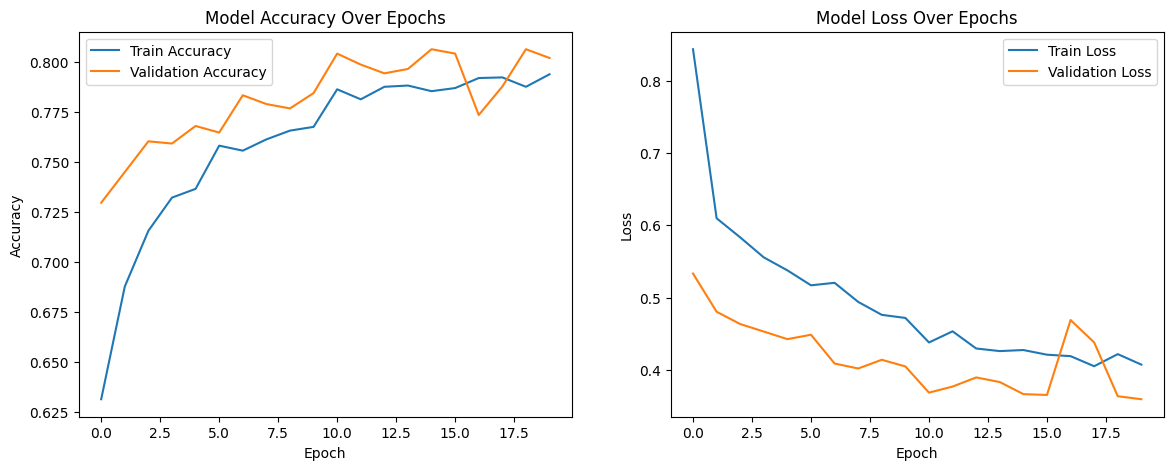

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Get number of classes from the dataset
num_classes = len(class_names)

# Build a simple CNN model
model = Sequential([
    Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(64, 64, 3)),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='sparse_categorical_crossentropy',  # No need for one-hot since labels are int
    metrics=['accuracy']
)

# Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train the model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[early_stop],
    verbose=2
)

# Evaluate on the test set
test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()


- learning curves show steady increase in train/val accuracy from ~ 0.63 to 0.80 and also the losses decrease correspondingly.
- Reported test accuracy is 0.8322.

**Optimizer Selection**

Using the Base model, we are evaluating it over 3 Optimizers : Adam,SGD,RMSprop.


Training with optimizer: adam
Epoch 1/20



Copying files: 1890 files [51:43,  1.64s/ files] 


100/100 ━━━━━━━━━━━━━━━━━━━━ 44s 141ms/step - accuracy: 0.5378 - loss: 1.1710 - val_accuracy: 0.7295 - val_loss: 0.5330
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 127ms/step - accuracy: 0.6725 - loss: 0.6430 - val_accuracy: 0.7371 - val_loss: 0.4843
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 130ms/step - accuracy: 0.7012 - loss: 0.6082 - val_accuracy: 0.7547 - val_loss: 0.4672
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 15s 151ms/step - accuracy: 0.7281 - loss: 0.5655 - val_accuracy: 0.7612 - val_loss: 0.4526
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 129ms/step - accuracy: 0.7320 - loss: 0.5494 - val_accuracy: 0.7831 - val_loss: 0.4217
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 19s 118ms/step - accuracy: 0.7497 - loss: 0.5214 - val_accuracy: 0.7809 - val_loss: 0.4205
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 127ms/step - accuracy: 0.7481 - loss: 0.5355 - val_accuracy: 0.7875 - val_loss: 0.4020
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 126ms/step - accuracy: 0.7551 - loss: 0.5025 - val

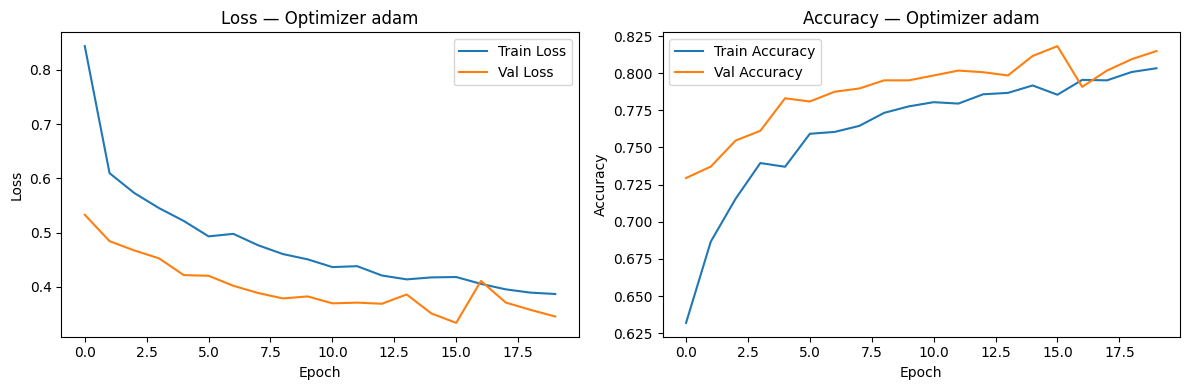


Training with optimizer: sgd
Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 15s 134ms/step - accuracy: 0.5365 - loss: 1.0279 - val_accuracy: 0.6867 - val_loss: 0.6371
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 120ms/step - accuracy: 0.6592 - loss: 0.7440 - val_accuracy: 0.7032 - val_loss: 0.5801
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 122ms/step - accuracy: 0.6842 - loss: 0.6554 - val_accuracy: 0.7152 - val_loss: 0.5511
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 115ms/step - accuracy: 0.6909 - loss: 0.6385 - val_accuracy: 0.7152 - val_loss: 0.5340
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - accuracy: 0.6929 - loss: 0.6186 - val_accuracy: 0.7415 - val_loss: 0.5189
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 116ms/step - accuracy: 0.7103 - loss: 0.5920 - val_accuracy: 0.7306 - val_loss: 0.5133
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 116ms/step - accuracy: 0.7086 - loss: 0.5861 - val_accuracy: 0.7415 - val_loss: 0.5019
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 123ms/ste

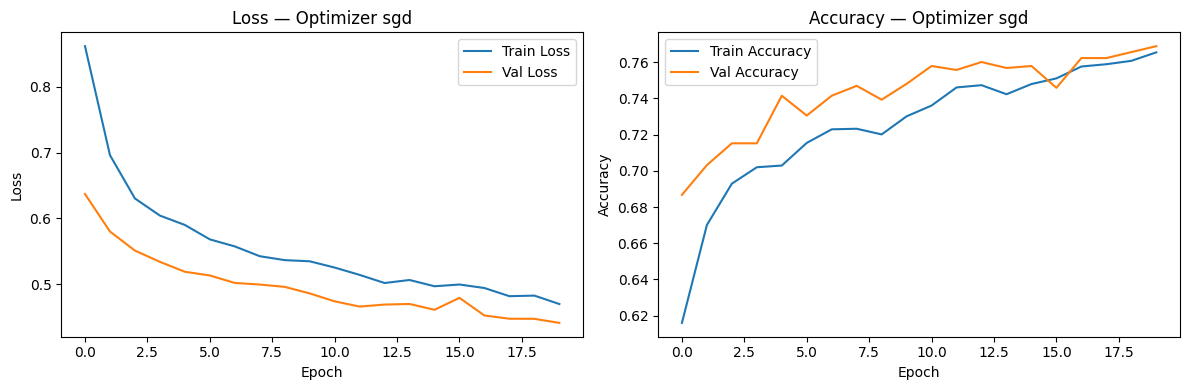


Training with optimizer: rmsprop
Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 16s 141ms/step - accuracy: 0.6029 - loss: 1.0360 - val_accuracy: 0.7119 - val_loss: 0.5761
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 125ms/step - accuracy: 0.7158 - loss: 0.5914 - val_accuracy: 0.7645 - val_loss: 0.4514
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 124ms/step - accuracy: 0.7262 - loss: 0.5489 - val_accuracy: 0.7733 - val_loss: 0.4493
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.7518 - loss: 0.5106 - val_accuracy: 0.7689 - val_loss: 0.4472
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 126ms/step - accuracy: 0.7600 - loss: 0.4964 - val_accuracy: 0.7744 - val_loss: 0.4203
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 121ms/step - accuracy: 0.7675 - loss: 0.4772 - val_accuracy: 0.7831 - val_loss: 0.4205
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 119ms/step - accuracy: 0.7710 - loss: 0.4516 - val_accuracy: 0.7820 - val_loss: 0.4038
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms

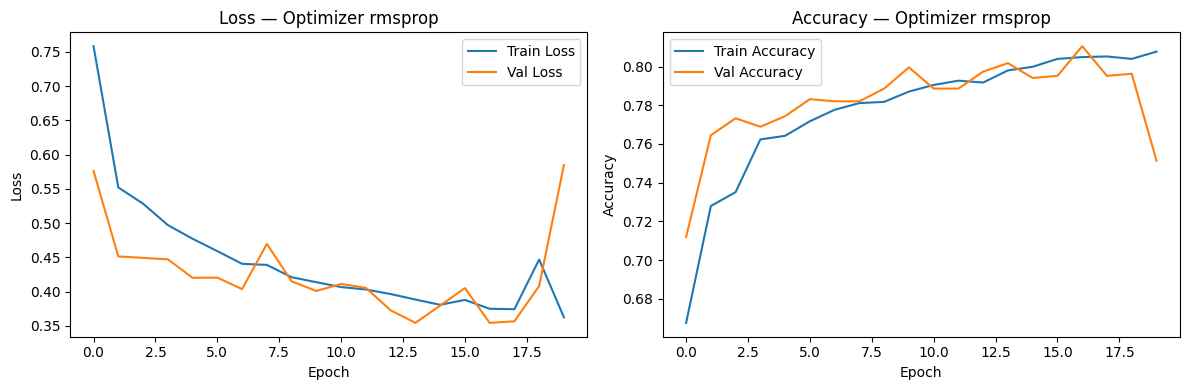


Best optimizer found: adam with validation accuracy: 0.8182


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
import matplotlib.pyplot as plt

# Fixed settings
input_shape = (64, 64, 3)  # Based on Step 2.1
num_classes = len(class_names)  # From dataset
batch_size = 32

# Optimizers to test
optimizers = {
    'adam': Adam(),
    'sgd': SGD(),
    'rmsprop': RMSprop()
}

best_val_accuracy = 0
best_optimizer = None

for opt_name, optimizer in optimizers.items():
    print(f"\nTraining with optimizer: {opt_name}")

    # Build CNN model
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)

    history = model.fit(
        train_dataset.batch(batch_size),
        validation_data=val_dataset.batch(batch_size),
        epochs=20,
        callbacks=[early_stop],
        verbose=1
    )

    max_val_acc = max(history.history['val_accuracy'])
    print(f"Max validation accuracy for optimizer {opt_name}: {max_val_acc:.4f}")

    # Plot Loss & Accuracy curves
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Loss — Optimizer {opt_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'Accuracy — Optimizer {opt_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

    if max_val_acc > best_val_accuracy:
        best_val_accuracy = max_val_acc
        best_optimizer = opt_name

print(f"\nBest optimizer found: {best_optimizer} with validation accuracy: {best_val_accuracy:.4f}")


- Max val accuracy: Adam 0.8182; SGD 0.7689; RMSprop 0.8105.
- Adam is delivering faster and more stable convergence on this CNN and datasets cale.
- Although RMSprop is competitive, SDG underperforms. So, Adam is the prefered optimizer for the base configuration

**Kernel size selection**

Using the tuned setup from optimizer selection, we are selecting a convolution kernel size from 3x3, 5x5, 7x7


Training with kernel size: (3, 3)
Epoch 1/20
100/100 - 18s - 181ms/step - accuracy: 0.6432 - loss: 0.8249 - val_accuracy: 0.7196 - val_loss: 0.5514
Epoch 2/20
100/100 - 14s - 135ms/step - accuracy: 0.7226 - loss: 0.5745 - val_accuracy: 0.7437 - val_loss: 0.5117
Epoch 3/20
100/100 - 14s - 137ms/step - accuracy: 0.7280 - loss: 0.5451 - val_accuracy: 0.7766 - val_loss: 0.4324
Epoch 4/20
100/100 - 11s - 114ms/step - accuracy: 0.7417 - loss: 0.5128 - val_accuracy: 0.7864 - val_loss: 0.4521
Epoch 5/20
100/100 - 11s - 109ms/step - accuracy: 0.7508 - loss: 0.5017 - val_accuracy: 0.7711 - val_loss: 0.4419
Epoch 6/20
100/100 - 12s - 116ms/step - accuracy: 0.7658 - loss: 0.4715 - val_accuracy: 0.7503 - val_loss: 0.5712
Epoch 7/20
100/100 - 12s - 118ms/step - accuracy: 0.7720 - loss: 0.4585 - val_accuracy: 0.7864 - val_loss: 0.3986
Epoch 8/20
100/100 - 12s - 117ms/step - accuracy: 0.7814 - loss: 0.4554 - val_accuracy: 0.7744 - val_loss: 0.4335
Epoch 9/20
100/100 - 12s - 118ms/step - accuracy: 0.7

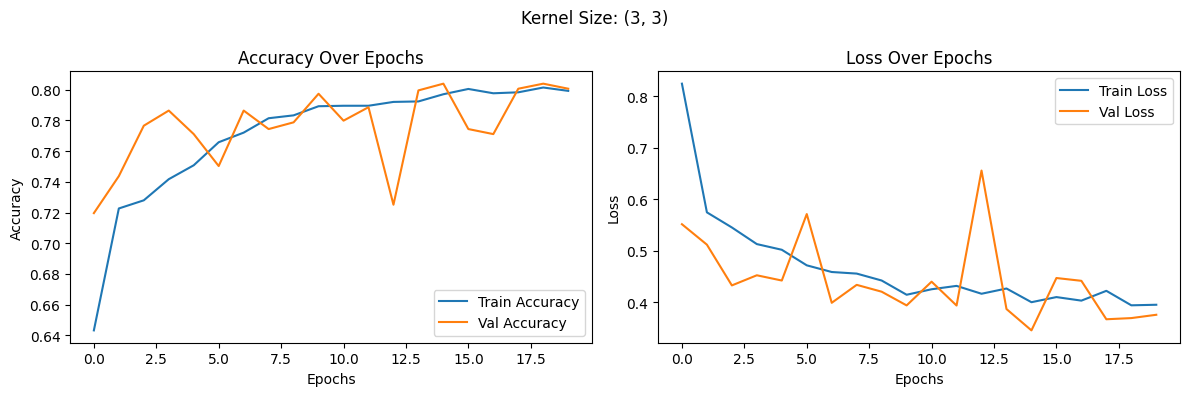


Training with kernel size: (5, 5)
Epoch 1/20
100/100 - 18s - 179ms/step - accuracy: 0.6188 - loss: 0.8878 - val_accuracy: 0.7218 - val_loss: 0.5657
Epoch 2/20
100/100 - 16s - 158ms/step - accuracy: 0.6989 - loss: 0.6243 - val_accuracy: 0.7426 - val_loss: 0.5106
Epoch 3/20
100/100 - 12s - 119ms/step - accuracy: 0.7208 - loss: 0.5683 - val_accuracy: 0.7492 - val_loss: 0.4750
Epoch 4/20
100/100 - 12s - 119ms/step - accuracy: 0.7455 - loss: 0.5286 - val_accuracy: 0.7185 - val_loss: 0.6682
Epoch 5/20
100/100 - 12s - 121ms/step - accuracy: 0.7492 - loss: 0.5217 - val_accuracy: 0.7766 - val_loss: 0.4455
Epoch 6/20
100/100 - 12s - 119ms/step - accuracy: 0.7542 - loss: 0.4983 - val_accuracy: 0.7733 - val_loss: 0.4266
Epoch 7/20
100/100 - 12s - 116ms/step - accuracy: 0.7627 - loss: 0.4997 - val_accuracy: 0.7667 - val_loss: 0.4483
Epoch 8/20
100/100 - 12s - 116ms/step - accuracy: 0.7667 - loss: 0.4754 - val_accuracy: 0.7886 - val_loss: 0.4008
Epoch 9/20
100/100 - 21s - 207ms/step - accuracy: 0.7

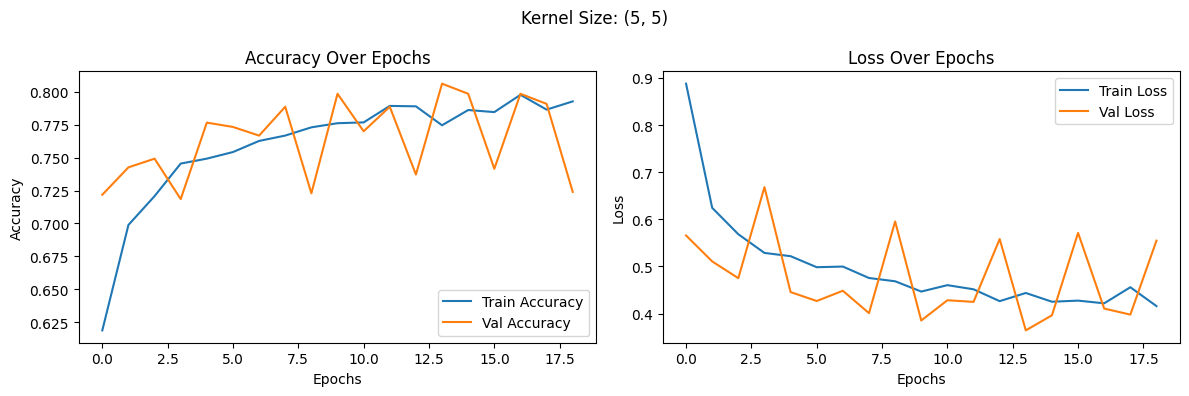


Training with kernel size: (7, 7)
Epoch 1/20
100/100 - 18s - 177ms/step - accuracy: 0.6248 - loss: 0.8314 - val_accuracy: 0.7141 - val_loss: 0.5761
Epoch 2/20
100/100 - 12s - 117ms/step - accuracy: 0.7023 - loss: 0.6155 - val_accuracy: 0.7284 - val_loss: 0.5296
Epoch 3/20
100/100 - 13s - 134ms/step - accuracy: 0.7098 - loss: 0.5828 - val_accuracy: 0.7415 - val_loss: 0.5291
Epoch 4/20
100/100 - 14s - 137ms/step - accuracy: 0.7273 - loss: 0.5791 - val_accuracy: 0.7645 - val_loss: 0.4695
Epoch 5/20
100/100 - 11s - 115ms/step - accuracy: 0.7326 - loss: 0.5447 - val_accuracy: 0.7371 - val_loss: 0.5020
Epoch 6/20
100/100 - 14s - 136ms/step - accuracy: 0.7458 - loss: 0.5178 - val_accuracy: 0.7766 - val_loss: 0.4221
Epoch 7/20
100/100 - 19s - 188ms/step - accuracy: 0.7458 - loss: 0.5277 - val_accuracy: 0.7831 - val_loss: 0.4221
Epoch 8/20
100/100 - 12s - 117ms/step - accuracy: 0.7570 - loss: 0.5046 - val_accuracy: 0.7788 - val_loss: 0.4257
Epoch 9/20
100/100 - 12s - 117ms/step - accuracy: 0.7

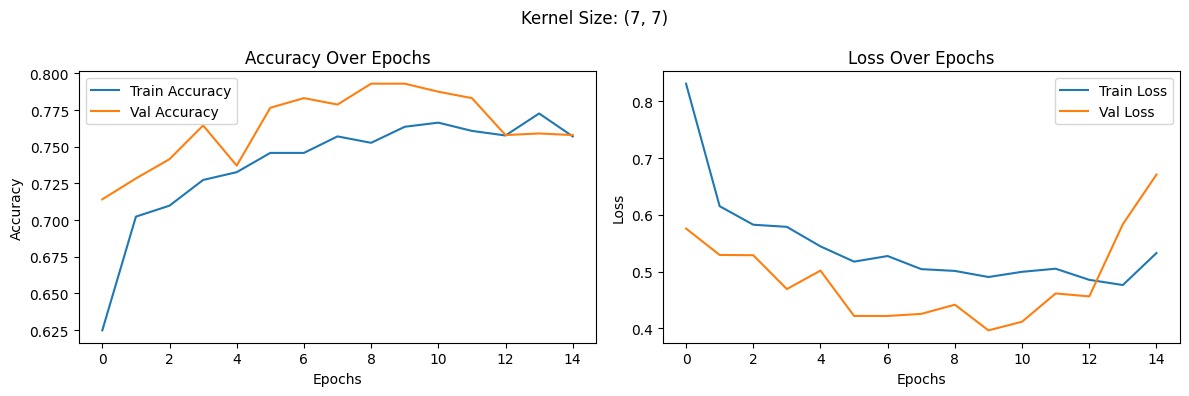


Training with kernel size: (9, 9)
Epoch 1/20
100/100 - 19s - 190ms/step - accuracy: 0.6345 - loss: 0.9991 - val_accuracy: 0.6616 - val_loss: 0.7489
Epoch 2/20
100/100 - 14s - 135ms/step - accuracy: 0.6692 - loss: 0.6847 - val_accuracy: 0.6944 - val_loss: 0.6608
Epoch 3/20
100/100 - 14s - 143ms/step - accuracy: 0.7092 - loss: 0.6191 - val_accuracy: 0.7459 - val_loss: 0.5128
Epoch 4/20
100/100 - 12s - 120ms/step - accuracy: 0.7167 - loss: 0.5815 - val_accuracy: 0.7382 - val_loss: 0.5786
Epoch 5/20
100/100 - 12s - 116ms/step - accuracy: 0.7273 - loss: 0.6042 - val_accuracy: 0.6857 - val_loss: 0.8240
Epoch 6/20
100/100 - 21s - 209ms/step - accuracy: 0.7333 - loss: 0.6011 - val_accuracy: 0.7568 - val_loss: 0.4771
Epoch 7/20
100/100 - 12s - 119ms/step - accuracy: 0.7495 - loss: 0.5650 - val_accuracy: 0.7404 - val_loss: 0.5107
Epoch 8/20
100/100 - 12s - 116ms/step - accuracy: 0.7380 - loss: 0.5835 - val_accuracy: 0.7251 - val_loss: 0.5181
Epoch 9/20
100/100 - 23s - 225ms/step - accuracy: 0.7

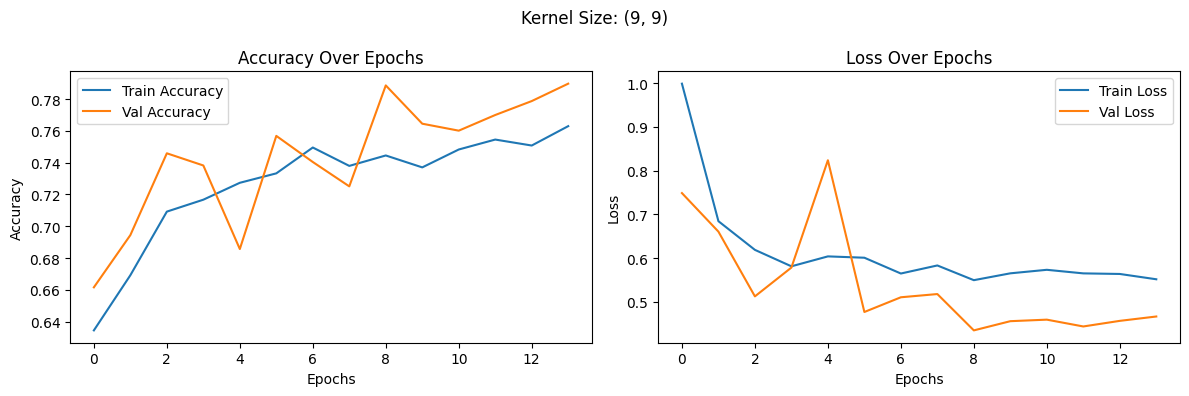

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop
import matplotlib.pyplot as plt

# Settings
input_shape = (64, 64, 3)  # From Step 2.1
num_classes = len(class_names)
batch_size = 32

# Kernel sizes to test
kernel_sizes = [(3, 3), (5, 5), (7, 7), (9, 9)]

# Dictionary to store results
kernel_results = {}

for kernel in kernel_sizes:
    print(f"\nTraining with kernel size: {kernel}")

    # Build CNN with given kernel size
    model = Sequential([
        Conv2D(32, kernel, activation='relu', padding='valid', input_shape=input_shape),
        MaxPooling2D((2, 2), padding='valid'),
        Conv2D(64, kernel, activation='relu', padding='valid'),
        MaxPooling2D((2, 2), padding='valid'),
        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=RMSprop(),  # Best optimizer from previous step
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    # Train
    history = model.fit(
                train_dataset,
        validation_data=val_dataset,
        epochs=20,
        callbacks=[early_stop],
        verbose=2
    )

    # Evaluate on test set
    test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
    print(f"Test Accuracy for kernel {kernel}: {test_acc:.4f}")

    # Save results
    kernel_results[str(kernel)] = {
        'history': history,
        'test_accuracy': test_acc
    }

    # Plot accuracy & loss
    plt.figure(figsize=(12, 4))
    plt.suptitle(f"Kernel Size: {kernel}")

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Accuracy Over Epochs')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Loss Over Epochs')
    plt.legend()

    plt.tight_layout()
    plt.show()


- Test accuracies: 3×3  0.8322; 5×5 0.8344; 7×7 0.8170; 9×9 0.7930.
- Learning curves show that 5x5 has higer peak accuracy but with visible validation oscillations whereas 7x7 had smoother validation loss descent with more stable accuracy plateau before late-epoch noise.
- Selecting 7x7 instead of 5x5 even if it has higher single point accuracy.

**Batch Size selection**

Using the selected kernel, we compare batch sizes: 16, 32, and 64.


Training with batch size: 16
Epoch 1/20


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


200/200 - 17s - 85ms/step - accuracy: 0.6445 - loss: 0.7974 - val_accuracy: 0.6944 - val_loss: 0.6211
Epoch 2/20
200/200 - 12s - 58ms/step - accuracy: 0.7011 - loss: 0.6255 - val_accuracy: 0.7590 - val_loss: 0.4772
Epoch 3/20
200/200 - 20s - 102ms/step - accuracy: 0.7289 - loss: 0.5806 - val_accuracy: 0.7656 - val_loss: 0.4689
Epoch 4/20
200/200 - 20s - 99ms/step - accuracy: 0.7280 - loss: 0.5714 - val_accuracy: 0.7667 - val_loss: 0.4771
Epoch 5/20
200/200 - 12s - 62ms/step - accuracy: 0.7427 - loss: 0.5608 - val_accuracy: 0.7547 - val_loss: 0.5083
Epoch 6/20
200/200 - 20s - 102ms/step - accuracy: 0.7455 - loss: 0.5418 - val_accuracy: 0.7700 - val_loss: 0.4437
Epoch 7/20
200/200 - 20s - 102ms/step - accuracy: 0.7514 - loss: 0.5330 - val_accuracy: 0.7623 - val_loss: 0.4693
Epoch 8/20
200/200 - 12s - 59ms/step - accuracy: 0.7489 - loss: 0.5150 - val_accuracy: 0.7897 - val_loss: 0.4318
Epoch 9/20
200/200 - 12s - 59ms/step - accuracy: 0.7517 - loss: 0.5692 - val_accuracy: 0.7579 - val_loss

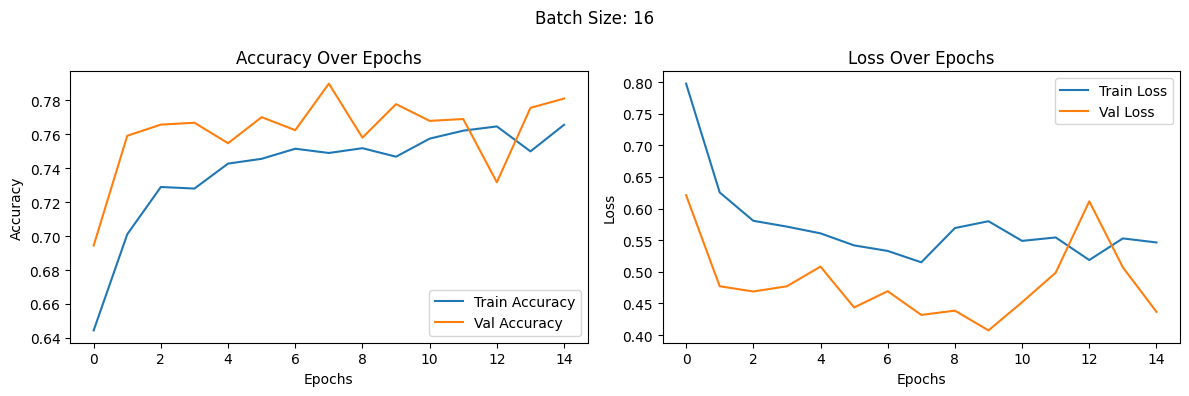


Training with batch size: 32
Epoch 1/20
100/100 - 16s - 163ms/step - accuracy: 0.6263 - loss: 0.8813 - val_accuracy: 0.7010 - val_loss: 0.6128
Epoch 2/20
100/100 - 11s - 110ms/step - accuracy: 0.6976 - loss: 0.6434 - val_accuracy: 0.7076 - val_loss: 0.6022
Epoch 3/20
100/100 - 21s - 211ms/step - accuracy: 0.7029 - loss: 0.5918 - val_accuracy: 0.7579 - val_loss: 0.4947
Epoch 4/20
100/100 - 11s - 114ms/step - accuracy: 0.7402 - loss: 0.5598 - val_accuracy: 0.7612 - val_loss: 0.4465
Epoch 5/20
100/100 - 11s - 114ms/step - accuracy: 0.7376 - loss: 0.5435 - val_accuracy: 0.7415 - val_loss: 0.4847
Epoch 6/20
100/100 - 20s - 201ms/step - accuracy: 0.7411 - loss: 0.5195 - val_accuracy: 0.7722 - val_loss: 0.4284
Epoch 7/20
100/100 - 21s - 210ms/step - accuracy: 0.7555 - loss: 0.5043 - val_accuracy: 0.7656 - val_loss: 0.4927
Epoch 8/20
100/100 - 12s - 116ms/step - accuracy: 0.7564 - loss: 0.5181 - val_accuracy: 0.7141 - val_loss: 0.6740
Epoch 9/20
100/100 - 20s - 200ms/step - accuracy: 0.7511 -

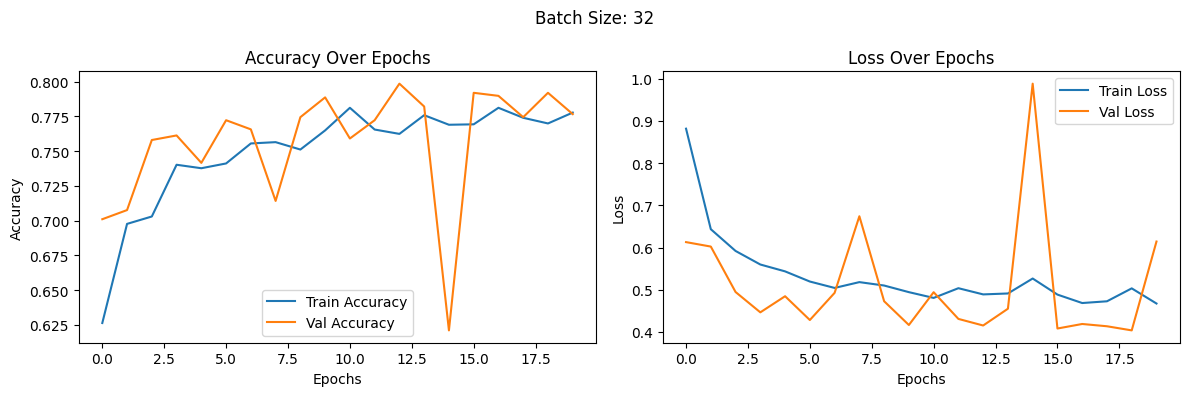


Training with batch size: 64
Epoch 1/20
50/50 - 18s - 359ms/step - accuracy: 0.5847 - loss: 1.0420 - val_accuracy: 0.6846 - val_loss: 0.6201
Epoch 2/20
50/50 - 12s - 247ms/step - accuracy: 0.6826 - loss: 0.6717 - val_accuracy: 0.7284 - val_loss: 0.5568
Epoch 3/20
50/50 - 12s - 244ms/step - accuracy: 0.6957 - loss: 0.6238 - val_accuracy: 0.7492 - val_loss: 0.5135
Epoch 4/20
50/50 - 12s - 240ms/step - accuracy: 0.7267 - loss: 0.5746 - val_accuracy: 0.7645 - val_loss: 0.4907
Epoch 5/20
50/50 - 12s - 240ms/step - accuracy: 0.7386 - loss: 0.5425 - val_accuracy: 0.7820 - val_loss: 0.4447
Epoch 6/20
50/50 - 21s - 416ms/step - accuracy: 0.7455 - loss: 0.5285 - val_accuracy: 0.7678 - val_loss: 0.4629
Epoch 7/20
50/50 - 11s - 227ms/step - accuracy: 0.7511 - loss: 0.5000 - val_accuracy: 0.7558 - val_loss: 0.4729
Epoch 8/20
50/50 - 12s - 233ms/step - accuracy: 0.7649 - loss: 0.4802 - val_accuracy: 0.7853 - val_loss: 0.4104
Epoch 9/20
50/50 - 12s - 234ms/step - accuracy: 0.7586 - loss: 0.4864 - va

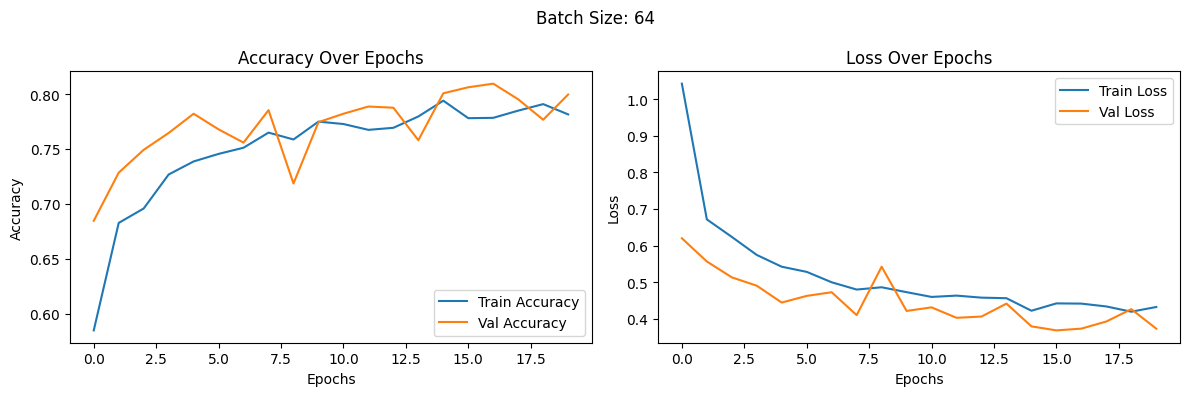


Best batch size: 64 with Validation Accuracy: 0.8094


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop
import matplotlib.pyplot as plt

# Settings
input_shape = (64, 64, 3)  # From Step 2.1
num_classes = len(class_names)

# Batch sizes to try
batch_sizes = [16, 32, 64]

# Track best result
best_val_accuracy = 0
best_batch = None

for bs in batch_sizes:
    print(f"\nTraining with batch size: {bs}")

    # Re-batch datasets for this batch size
    train_ds = train_dataset.unbatch().batch(bs)
    val_ds = val_dataset.unbatch().batch(bs)
    test_ds = test_dataset.unbatch().batch(bs)

    # Build CNN model with best kernel 7x7
    model = Sequential([
        Input(shape=input_shape),
        Conv2D(32, (7, 7), activation='relu', padding='valid'),
        MaxPooling2D((2, 2), padding='valid'),
        Conv2D(64, (7, 7), activation='relu', padding='valid'),
        MaxPooling2D((2, 2), padding='valid'),
        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])

    # Compile
    model.compile(
        optimizer=RMSprop(),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Early stopping
    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    # Train
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=20,
        callbacks=[early_stop],
        verbose=2
    )

    # Evaluate on test set
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    print(f"Test Accuracy for batch size {bs}: {test_acc:.4f}")

    if max(history.history['val_accuracy']) > best_val_accuracy:
        best_val_accuracy = max(history.history['val_accuracy'])
        best_batch = bs

    # Plotting
    plt.figure(figsize=(12, 4))
    plt.suptitle(f"Batch Size: {bs}")

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Accuracy Over Epochs')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Loss Over Epochs')
    plt.legend()

    plt.tight_layout()
    plt.show()

print(f"\nBest batch size: {best_batch} with Validation Accuracy: {best_val_accuracy:.4f}")


- Test accuracies: 16 0.8083; 32 0.8061; 64 0.8148
- Best validation accuracy is observed with batch size 64 and the curves show smooth loss decay and stable validation accuracy.
- The larger batch (64) provides steadier gradient estimates for this setup and also has more validation stability compared to 16/32.
- So, 64 batch size is chosen.

**Regularization Comparison**

Using the chosen batch size, we test regularization strategies: none, Dropout, and L2.


Training with none regularization...
Epoch 1/20
100/100 - 61s - 609ms/step - accuracy: 0.6245 - loss: 0.7967 - val_accuracy: 0.6440 - val_loss: 0.6798
Epoch 2/20
100/100 - 59s - 592ms/step - accuracy: 0.7064 - loss: 0.5862 - val_accuracy: 0.7667 - val_loss: 0.4930
Epoch 3/20
100/100 - 58s - 583ms/step - accuracy: 0.7439 - loss: 0.5313 - val_accuracy: 0.6867 - val_loss: 0.6356
Epoch 4/20
100/100 - 59s - 588ms/step - accuracy: 0.7430 - loss: 0.5104 - val_accuracy: 0.7689 - val_loss: 0.4590
Epoch 5/20
100/100 - 63s - 630ms/step - accuracy: 0.7467 - loss: 0.4887 - val_accuracy: 0.7645 - val_loss: 0.4636
Epoch 6/20
100/100 - 57s - 572ms/step - accuracy: 0.7724 - loss: 0.4662 - val_accuracy: 0.7798 - val_loss: 0.4617
Epoch 7/20
100/100 - 82s - 817ms/step - accuracy: 0.7689 - loss: 0.4471 - val_accuracy: 0.7349 - val_loss: 0.5016
Epoch 8/20
100/100 - 60s - 605ms/step - accuracy: 0.7649 - loss: 0.4489 - val_accuracy: 0.7766 - val_loss: 0.4360
Epoch 9/20
100/100 - 61s - 614ms/step - accuracy: 

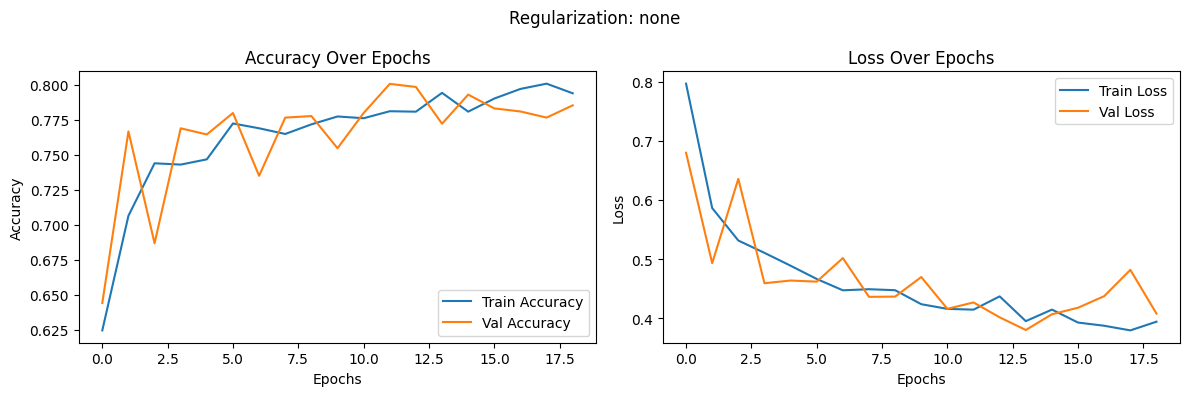


Training with dropout regularization...
Epoch 1/20
100/100 - 61s - 606ms/step - accuracy: 0.5804 - loss: 0.9643 - val_accuracy: 0.7174 - val_loss: 0.5874
Epoch 2/20
100/100 - 84s - 837ms/step - accuracy: 0.6723 - loss: 0.7082 - val_accuracy: 0.6824 - val_loss: 0.6336
Epoch 3/20
100/100 - 57s - 570ms/step - accuracy: 0.6842 - loss: 0.6433 - val_accuracy: 0.6933 - val_loss: 0.7066
Epoch 4/20
100/100 - 60s - 602ms/step - accuracy: 0.7039 - loss: 0.6242 - val_accuracy: 0.7393 - val_loss: 0.5024
Epoch 5/20
100/100 - 60s - 604ms/step - accuracy: 0.7089 - loss: 0.5997 - val_accuracy: 0.7207 - val_loss: 0.5408
Epoch 6/20
100/100 - 61s - 607ms/step - accuracy: 0.7126 - loss: 0.5901 - val_accuracy: 0.7470 - val_loss: 0.5016
Epoch 7/20
100/100 - 58s - 576ms/step - accuracy: 0.7255 - loss: 0.5448 - val_accuracy: 0.7568 - val_loss: 0.4937
Epoch 8/20
100/100 - 58s - 581ms/step - accuracy: 0.7420 - loss: 0.5308 - val_accuracy: 0.7864 - val_loss: 0.4305
Epoch 9/20
100/100 - 85s - 851ms/step - accurac

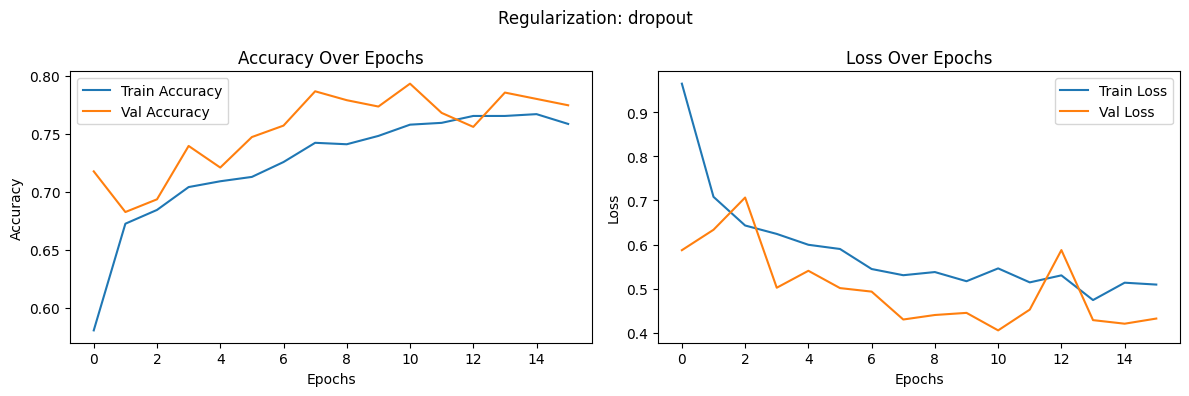


Training with l2 regularization...
Epoch 1/20
100/100 - 62s - 624ms/step - accuracy: 0.6307 - loss: 1.0290 - val_accuracy: 0.6900 - val_loss: 0.7036
Epoch 2/20
100/100 - 61s - 612ms/step - accuracy: 0.7042 - loss: 0.6917 - val_accuracy: 0.7262 - val_loss: 0.5945
Epoch 3/20
100/100 - 57s - 571ms/step - accuracy: 0.7251 - loss: 0.6169 - val_accuracy: 0.6484 - val_loss: 0.9490
Epoch 4/20
100/100 - 61s - 609ms/step - accuracy: 0.7402 - loss: 0.5727 - val_accuracy: 0.7656 - val_loss: 0.5355
Epoch 5/20
100/100 - 76s - 762ms/step - accuracy: 0.7552 - loss: 0.5479 - val_accuracy: 0.7656 - val_loss: 0.4804
Epoch 6/20
100/100 - 84s - 836ms/step - accuracy: 0.7658 - loss: 0.5142 - val_accuracy: 0.7601 - val_loss: 0.5088
Epoch 7/20
100/100 - 58s - 577ms/step - accuracy: 0.7592 - loss: 0.5093 - val_accuracy: 0.7568 - val_loss: 0.5178
Epoch 8/20
100/100 - 81s - 808ms/step - accuracy: 0.7642 - loss: 0.5038 - val_accuracy: 0.7722 - val_loss: 0.5055
Epoch 9/20
100/100 - 60s - 603ms/step - accuracy: 0.

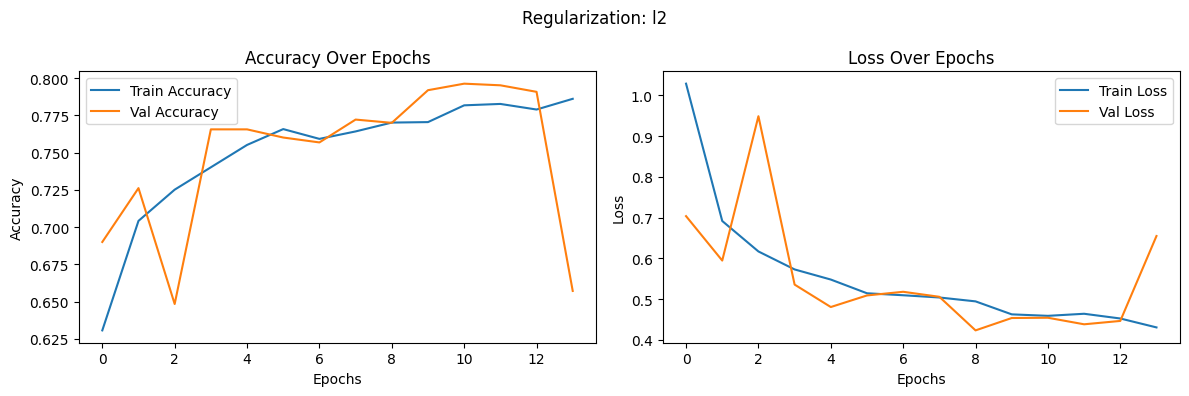

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop
import matplotlib.pyplot as plt

# Settings
input_shape = (64, 64, 3)
num_classes = len(class_names)
batch_size = 64  # Already set in datasets
epochs = 20
patience = 5

# Regularizations to try
regularizations = ['none', 'dropout', 'l2']
histories = {}

for reg in regularizations:
    print(f"\nTraining with {reg} regularization...")

    # Build CNN model
    model = Sequential()
    model.add(Input(shape=input_shape))
    # Conv layers with best kernel
    model.add(Conv2D(32, (7, 7), activation='relu', padding='valid'))
    model.add(MaxPooling2D((2, 2), padding='valid'))
    model.add(Conv2D(64, (7, 7), activation='relu', padding='valid'))
    model.add(MaxPooling2D((2, 2), padding='valid'))
    model.add(Flatten())

    # Dense layers with chosen regularization
    if reg == 'dropout':
        model.add(Dense(64, activation='relu'))
        model.add(Dropout(0.5))
        model.add(Dense(64, activation='relu'))
        model.add(Dropout(0.5))
    elif reg == 'l2':
        model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.001)))
        model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.001)))
    else:
        model.add(Dense(64, activation='relu'))
        model.add(Dense(64, activation='relu'))

    # Output layer
    model.add(Dense(num_classes, activation='softmax'))

    # Compile
    model.compile(
        optimizer=RMSprop(),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Early stopping
    early_stop = EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)

    # Train
    history = model.fit(
        train_dataset,       
        validation_data=val_dataset,  
        epochs=epochs,
        callbacks=[early_stop],
        verbose=2
    )

    # Evaluate
    test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
    print(f"Test Accuracy with {reg} regularization: {test_acc:.4f}")

    histories[reg] = history

    # Plotting
    plt.figure(figsize=(12, 4))
    plt.suptitle(f"Regularization: {reg}")

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Accuracy Over Epochs')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Loss Over Epochs')
    plt.legend()

    plt.tight_layout()
    plt.show()


- Test accuracies: none 0.7800; dropout 0.8126; L2 0.7952.
- Curves show dropout reduces the train-val gap and is yielding more consistent validation loss.
- dropout is the most effective at controlling overfitting in this shallow network and limited input resolution, imporving generalization over L2 in this configuration.
- L2 reduces variance but slightly underfits relative to dropout.
- So, dropout is chosen.

**Finalized Baseline CNN**

Using the best regularization, we finalize and evaluate the baseline CNN configuration.

Based on the hyperparameter tuning (optimizer, kernel, batch size, and regularization), the finalized baseline CNN uses 64×64×3 inputs with two conv blocks of 7×7 filters (32→64) and max pooling, followed by a compact head: Flatten → Dense(64) + Dropout(0.5) → Dense(64) + Dropout(0.5) → Softmax(4). Trained with RMSprop, sparse categorical cross‑entropy, accuracy metric, batch size 64, and early stopping (patience 5)



Training CNN with Dropout regularization...
Epoch 1/20
100/100 - 58s - 581ms/step - accuracy: 0.5772 - loss: 0.9208 - val_accuracy: 0.6758 - val_loss: 0.6178
Epoch 2/20
100/100 - 55s - 550ms/step - accuracy: 0.6635 - loss: 0.7159 - val_accuracy: 0.7054 - val_loss: 0.6394
Epoch 3/20
100/100 - 55s - 551ms/step - accuracy: 0.6723 - loss: 0.6804 - val_accuracy: 0.7327 - val_loss: 0.5168
Epoch 4/20
100/100 - 82s - 823ms/step - accuracy: 0.6807 - loss: 0.6412 - val_accuracy: 0.7273 - val_loss: 0.5291
Epoch 5/20
100/100 - 85s - 851ms/step - accuracy: 0.7154 - loss: 0.6241 - val_accuracy: 0.7601 - val_loss: 0.4858
Epoch 6/20
100/100 - 75s - 753ms/step - accuracy: 0.7251 - loss: 0.6142 - val_accuracy: 0.7689 - val_loss: 0.4517
Epoch 7/20
100/100 - 54s - 543ms/step - accuracy: 0.7226 - loss: 0.5850 - val_accuracy: 0.7656 - val_loss: 0.5027
Epoch 8/20
100/100 - 85s - 850ms/step - accuracy: 0.7317 - loss: 0.5783 - val_accuracy: 0.7798 - val_loss: 0.4253
Epoch 9/20
100/100 - 58s - 585ms/step - acc

Test Accuracy with Dropout regularization: 0.8126
Model saved as cnn_dropout_best.h5 and cnn_dropout_best.keras


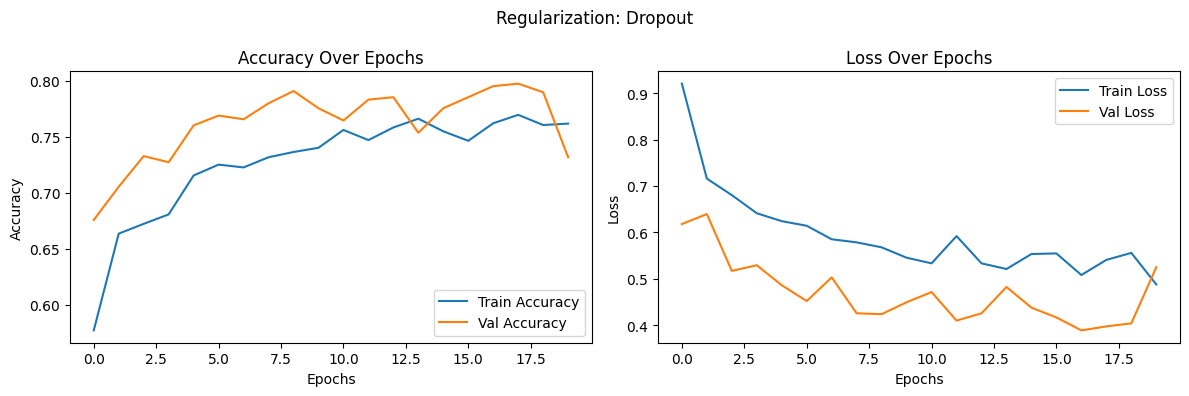

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop
import matplotlib.pyplot as plt

# Settings
IMG_SIZE = (64, 64)
BATCH_SIZE = 64
input_shape = (64, 64, 3)
num_classes = 4  # maize dataset has 4 classes
epochs = 20
patience = 5



print("\nTraining CNN with Dropout regularization...")

# Build CNN model with named last Conv2D layer
model = Sequential()
model.add(Input(shape=input_shape))

# Conv layers
model.add(Conv2D(32, (7, 7), activation='relu', padding='valid'))
model.add(MaxPooling2D((2, 2), padding='valid'))
model.add(Conv2D(64, (7, 7), activation='relu', padding='valid', name="last_conv"))
model.add(MaxPooling2D((2, 2), padding='valid'))
model.add(Flatten())

# Dense layers with Dropout
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5))

# Output layer
model.add(Dense(num_classes, activation='softmax'))

# Compile model
model.compile(
    optimizer=RMSprop(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)

# Train model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=epochs,
    callbacks=[early_stop],
    verbose=2
)

# Evaluate
test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print(f"Test Accuracy with Dropout regularization: {test_acc:.4f}")

# Save model
model.save("cnn_dropout_best.h5")
model.save("cnn_dropout_best.keras")
print("Model saved as cnn_dropout_best.h5 and cnn_dropout_best.keras")

# Plot training history
plt.figure(figsize=(12, 4))
plt.suptitle("Regularization: Dropout")

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy Over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss Over Epochs')
plt.legend()

plt.tight_layout()
plt.show()


- test accuracy: 0.8126.
- training curves show steadily improving accuracy with bounded overfitting.
- This configuration balances stability, speed, and generalization:
    1. 7×7 kernels for stable validation behavior and consistent context capture.
    2. Batch size 64 for smoother gradients and efficient training.
    3. Dropout to mitigate overfitting.

The named last_conv layer prepares the baseline for Grad-CAM in the XAI section.


The baseline CNN achieves an accuracy of 0.8126 test accuracy with stable training dynamics after tuning optimizer, kernel, batch size and regularization.

**Blackbox Model 2: EfficientNetB3**

Our goal here is to build on the baseline by leveraging pretrained visual features. We start with a frozen EfficientNetB3  to establish a transfer baseline, then finetune the upper layers with light agumentation for adapting to maize leaf textures and lesions.

EfficientNetB3 is chosen beacuse it is a leading model for visual tasks which is known for its accuracy and efficiency. Using a pretrained model allows us to transfer rich, general purpose feature representations learned from millions of natural images, saving compute and often performing better than models trained from scratch.

we are using the input size as 300×300 beacuse  EfficientNetB3 is pretrained at 300×300 which matches its native resolution preserves the receptive fields and feature scales it learned on ImageNet, avoids extra internal resampling, and works best with its preprocessing statistics.

Transfer learning(**which is one of the emerging technologies**) with EfficientNetB3 leverages prior knowledge to compensate for the relatively smaller size and domain specificity of your dataset, accelerating convergence and often improving accuracy compared to training a CNN from scratch

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
100/100 - 768s - 8s/step - accuracy: 0.5457 - loss: 1.1450 - val_accuracy: 0.6177 - val_loss: 0.9607
Epoch 2/20
100/100 - 20s - 205ms/step - accuracy: 0.5838 - loss: 1.0373 - val_accuracy: 0.6166 - val_loss: 0.9031
Epoch 3/20
100/100 - 19s - 189ms/step - accuracy: 0.5932 - loss: 0.9889 - val_accuracy: 0.6123 - val_loss: 0.8898
Epoch 4/20
100/100 - 19s - 186ms/step - accuracy: 0.6101 - loss: 0.9506 - val_accuracy: 0.6265 - val_loss: 0.8361
Epoch 5/20
100/100 - 24s - 242ms/step - accuracy: 0.6060 - loss: 0.9437 - val_accuracy: 0.6287 - val_loss: 0.8286
Epoch 6/20
100/100 - 19s - 185ms/step - accuracy: 0.6094 - loss: 0.9225 - val_accuracy: 0.6681 - val_loss: 0.7997
Epoch 7/20
100/100 - 24s - 245ms/step - accuracy: 0.6198 - loss: 0.9078 - val_accuracy: 0.6353 - val_loss: 0.8078
Epoch 8/20
100/100 - 34s - 339ms/step - accuracy: 0.6282 - loss: 0.8831 - val_accuracy: 0.6375 - val_loss: 0.7809
Epoch 9/20
100/100 - 20s - 198ms/step -

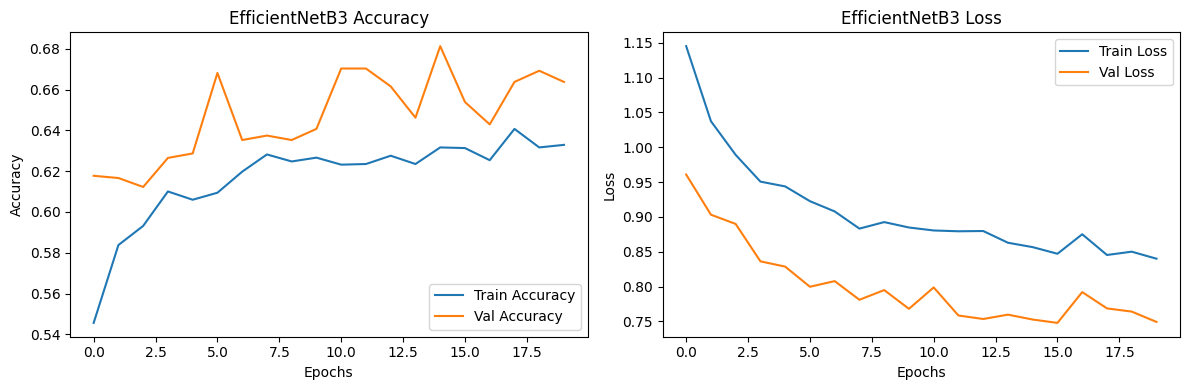

Model saved as efficientnetb3_maize.keras


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop
import matplotlib.pyplot as plt

# --- Settings ---
input_shape = (300, 300, 3)        # EfficientNetB3 input
num_classes = len(class_names)     # Number of classes in maize dataset
batch_size = 64
epochs = 20
patience = 5

# --- Preprocessing function ---
def preprocess_image(image, label):
    image = tf.image.resize(image, [300, 300])
    image = preprocess_input(image)  # scales pixels to [-1, 1]
    return image, label

# Apply preprocessing 
train_dataset = train_dataset.map(preprocess_image).prefetch(tf.data.AUTOTUNE)
val_dataset   = val_dataset.map(preprocess_image).prefetch(tf.data.AUTOTUNE)
test_dataset  = test_dataset.map(preprocess_image).prefetch(tf.data.AUTOTUNE)

# --- Build EfficientNetB3 Transfer Learning model ---
base_model = EfficientNetB3(
    include_top=False,       # Exclude default classification head
    weights='imagenet',      # Pretrained on ImageNet
    input_shape=input_shape
)

base_model.trainable = False  # Freeze all base layers

# Add custom classification head
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

# Compile
model.compile(
    optimizer=RMSprop(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)

# --- Train the model ---
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=epochs,
    callbacks=[early_stop],
    verbose=2
)

# --- Evaluate on test set ---
test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")

# --- Plot training history ---
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('EfficientNetB3 Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('EfficientNetB3 Loss')
plt.legend()

plt.tight_layout()
plt.show()

# --- Save the trained model ---
model.save('efficientnetb3_maize.keras')  # Native Keras format
print("Model saved as efficientnetb3_maize.keras")


- Test accuracy: 0.6601
- From the graphs we can say that the validation accuracy steadily increases and outperforms training accuracy, while both losses decrease across epochs without divergence.

Training only the head with a frozen backbone is fast and can reveal if high level ImageNet features are immediately useful. The model learns, but is underfit to the maize domain, could be due to ImageNet testures being only partially overlapping with plant disease cues. This is evident by the lower accuracy when compared to the base CNN model. This also confirms more adaptation is needed. 

**Data augumentation and stage fine tuning of EfficientNet**

Data is augmented with random horizontal flip, small rotation, and zoom, making the network robust to pose and framing variance.

First, the EfficientNetB3 backbone is frozen and a new head is trained (higher learning rate, up to 15 epochs, early stopping).

Next, the final ~50 layers of EfficientNetB3 are unfrozen and fine-tuned with a much lower learning rate (epochs up to 20, early stopping continues).

Epoch 1/15
100/100 - 56s - 560ms/step - accuracy: 0.5353 - loss: 1.1276 - val_accuracy: 0.6429 - val_loss: 0.8804
Epoch 2/15
100/100 - 34s - 340ms/step - accuracy: 0.5835 - loss: 1.0100 - val_accuracy: 0.6188 - val_loss: 0.9031
Epoch 3/15
100/100 - 34s - 339ms/step - accuracy: 0.5891 - loss: 0.9789 - val_accuracy: 0.6298 - val_loss: 0.8944
Epoch 4/15
100/100 - 37s - 369ms/step - accuracy: 0.6032 - loss: 0.9525 - val_accuracy: 0.6429 - val_loss: 0.7895
Epoch 5/15
100/100 - 38s - 378ms/step - accuracy: 0.5994 - loss: 0.9429 - val_accuracy: 0.6298 - val_loss: 0.8278
Epoch 6/15
100/100 - 42s - 423ms/step - accuracy: 0.6066 - loss: 0.9309 - val_accuracy: 0.6353 - val_loss: 0.8412
Epoch 1/20
100/100 - 65s - 655ms/step - accuracy: 0.5122 - loss: 1.0999 - val_accuracy: 0.6320 - val_loss: 0.8479
Epoch 2/20
100/100 - 80s - 798ms/step - accuracy: 0.5951 - loss: 0.9495 - val_accuracy: 0.6210 - val_loss: 0.8456
Epoch 3/20
100/100 - 40s - 398ms/step - accuracy: 0.6132 - loss: 0.9171 - val_accuracy: 

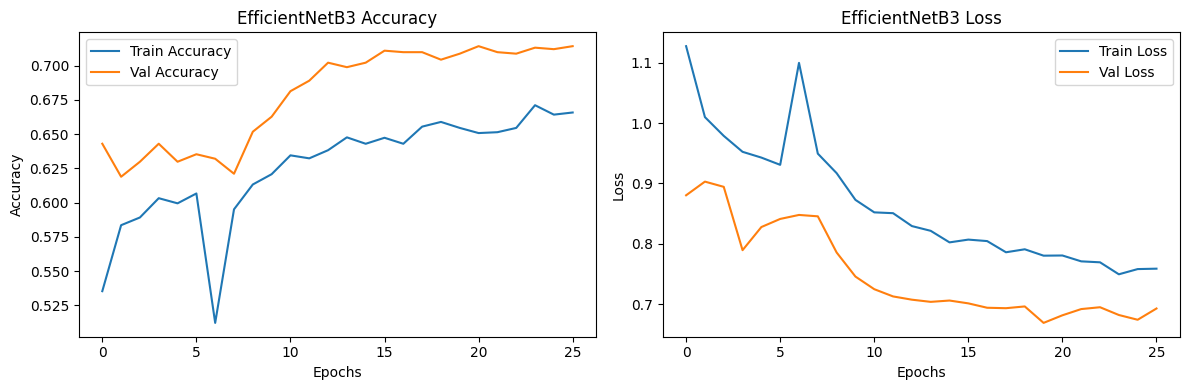

Model saved as efficientnetb3_maize_finetuned_v2.keras


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop
import matplotlib.pyplot as plt

# --- Settings ---
input_shape = (300, 300, 3)
num_classes = len(class_names)
batch_size = 64
epochs_frozen = 15
epochs_finetune = 20
patience = 5

# --- Preprocessing function ---
def preprocess_image(image, label):
    image = tf.image.resize(image, [300, 300])
    return image, label

# Apply preprocessing only as the datasets were already batched
train_dataset = train_dataset.map(preprocess_image).prefetch(tf.data.AUTOTUNE)
val_dataset   = val_dataset.map(preprocess_image).prefetch(tf.data.AUTOTUNE)
test_dataset  = test_dataset.map(preprocess_image).prefetch(tf.data.AUTOTUNE)

# --- Data augmentation ---
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="data_augmentation")

# --- Base model ---
base_model = EfficientNetB3(include_top=False, weights="imagenet", input_shape=input_shape)
base_model.trainable = False

# --- Build model ---
inputs = layers.Input(shape=input_shape)
x = data_augmentation(inputs)
x = preprocess_input(x)                # EfficientNet scaling
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model = models.Model(inputs, outputs)

# --- Compile ---
model.compile(
    optimizer=RMSprop(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# --- Frozen training ---
early_stop = EarlyStopping(monitor="val_accuracy", patience=patience, restore_best_weights=True)
history_frozen = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=epochs_frozen,
    callbacks=[early_stop],
    verbose=2
)

# --- Fine-tuning ---
base_model.trainable = True
for layer in base_model.layers[:-50]:  # freeze most layers
    layer.trainable = False

model.compile(
    optimizer=RMSprop(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_finetune = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=epochs_finetune,
    callbacks=[early_stop],
    verbose=2
)

# --- Evaluate ---
test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")

# --- Plot training history ---
plt.figure(figsize=(12, 4))
# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_frozen.history['accuracy'] + history_finetune.history['accuracy'], label='Train Accuracy')
plt.plot(history_frozen.history['val_accuracy'] + history_finetune.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('EfficientNetB3 Accuracy')
plt.legend()
# Loss
plt.subplot(1, 2, 2)
plt.plot(history_frozen.history['loss'] + history_finetune.history['loss'], label='Train Loss')
plt.plot(history_frozen.history['val_loss'] + history_finetune.history['val_loss'], label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('EfficientNetB3 Loss')
plt.legend()
plt.tight_layout()
plt.show()

# --- Save model ---
model.save('efficientnetb3_maize_finetuned_v2.keras')
print("Model saved as efficientnetb3_maize_finetuned_v2.keras")

- Test accuracy: 0.6993
- From the graphs we observed that the Validation accuracy improves over train accuracy and continues to rise during the fine-tuning and the validation loss drops sharply after unfreezing which is signaling effective adaptation to the maize disease detection task.

Fine tuning the upper layers allows the model to shift its high level feature detectors from the generic ImageNet objects to maize specific textures and lesion patterns where data augmentation helps prevent overfitting. The sharp curve in the graphs suggest that there is a effective transfer of domain specific cues like leaf texture and lesions. the boosted test accuracy compared to test trials indicates there is meaningful generalization improvement but the mode still fall flats compared to baseline CNN.

Stepwise transfer learning with EfficientNetB3 improved the model from a mostly domain-generic classifier to one with some maize-specific awareness, as seen from the clear improvements after fine-tuning. The systematic trials validate each choice and are revealing the impact of each change in pipeline, supporting future reproducibility and transparency. These results set the stage for our glassbox approach—using EfficientNetB3 as a robust feature extractor and training interpretable models (like a Decision Tree) on its embeddings, integrating interpretability without sacrificing all of the benefits of transfer learning.

**Glassbox Model 1: Decision Tree**

Here, we aim to make a maize leaf disease predictions fully interpretable by training a decision tree classifier not on raw pixels but from the features extracted from EfficientNetB3 model which was pretrained and fine tuned for this task. In doing so, we combine high level, discriminative representations with the transparent descision logic of a tree, enabling both strong performance and clear step by step explainations.

Instead of using the pixel values or any hand-crafted features, we leverage the output of EfficientNetB3's GlobalAveragePooling layer, which encapsulates high-level, task-relevant information about each image. We also concatenate basic statistics (mean, std, min, max per channel) to boost interpretability and capture global image patterns.

Fixed input shape (300×300): Follows EfficientNetB3's architecture and ensures consistency.

In [ ]:
# ====== IMPORTS ======
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier, export_text
import joblib
import matplotlib.pyplot as plt

# ====== SETTINGS ======
INPUT_SHAPE = (300, 300, 3)
NUM_CLASSES = len(class_names)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

def preprocess_image(image, label):
     image = tf.image.resize(image, [300, 300])
     image = preprocess_input(image)
     return image, label
train_dataset = train_dataset.map(preprocess_image).prefetch(tf.data.AUTOTUNE)
val_dataset   = val_dataset.map(preprocess_image).prefetch(tf.data.AUTOTUNE)
test_dataset  = test_dataset.map(preprocess_image).prefetch(tf.data.AUTOTUNE)





In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model, Model
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

# ------------------------------
# SETTINGS
# ------------------------------
INPUT_SHAPE = (300, 300, 3)
ADD_IMAGE_STATS = True  # Add mean, std, min, max per channel
RANDOM_SEED = 42

# ------------------------------
# STEP 4: FEATURE EXTRACTION
# ------------------------------
# Load fine-tuned model
finetuned_model = load_model('efficientnetb3_maize_finetuned_69.keras')

# Remove classification head
feature_extractor = Model(
    inputs=finetuned_model.input,
    outputs=finetuned_model.layers[-3].output  # GlobalAveragePooling2D output
)
feature_extractor.trainable = False

@tf.function
def fe_forward(images):
    return feature_extractor(images, training=False)

# Function to compute extra image features
def compute_image_stats(images):
    # images: batch_size x H x W x C
    mean = tf.reduce_mean(images, axis=[1,2])
    std  = tf.math.reduce_std(images, axis=[1,2])
    min_ = tf.reduce_min(images, axis=[1,2])
    max_ = tf.reduce_max(images, axis=[1,2])
    return tf.concat([mean, std, min_, max_], axis=1)

# Extract features and optional extra stats
def extract_features(ds, add_stats=True):
    feats_list, labels_list = [], []
    for batch_imgs, batch_labels in ds:
        cnn_feats = fe_forward(batch_imgs).numpy()
        if add_stats:
            stats_feats = compute_image_stats(batch_imgs).numpy()
            batch_feats = np.concatenate([cnn_feats, stats_feats], axis=1)
        else:
            batch_feats = cnn_feats
        feats_list.append(batch_feats)
        labels_list.append(batch_labels.numpy())
    X = np.concatenate(feats_list, axis=0)
    y = np.concatenate(labels_list, axis=0)
    return X, y

print("Extracting features (train)...")
X_train, y_train = extract_features(train_dataset, ADD_IMAGE_STATS)
print("Extracting features (val)...")
X_val, y_val = extract_features(val_dataset, ADD_IMAGE_STATS)
print("Extracting features (test)...")
X_test, y_test = extract_features(test_dataset, ADD_IMAGE_STATS)

print("Feature shapes:")
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

# Save features
np.savez_compressed("efficientnetB3_features_with_stats.npz",
                    X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test)
print("Saved features to efficientnetB3_features_with_stats.npz")



Extracting features (train)...
Extracting features (val)...
Extracting features (test)...
Feature shapes:
X_train: (3198, 1548)
X_val  : (913, 1548)
X_test : (459, 1548)
Saved features to efficientnetB3_features_with_stats.npz


Training Decision Tree...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Decision Tree best params: {'min_samples_split': 4, 'min_samples_leaf': 4, 'max_depth': 6, 'criterion': 'gini', 'ccp_alpha': 0.005}
Validation Accuracy (DT): 0.6067907995618839
Test Accuracy (DT): 0.6492374727668845
Classification Report (DT):
               precision    recall  f1-score   support

           0       0.25      0.94      0.40        52
           1       1.00      1.00      1.00       120
           2       0.56      0.10      0.17        99
           3       0.94      0.63      0.76       188

    accuracy                           0.65       459
   macro avg       0.69      0.67      0.58       459
weighted avg       0.80      0.65      0.65       459



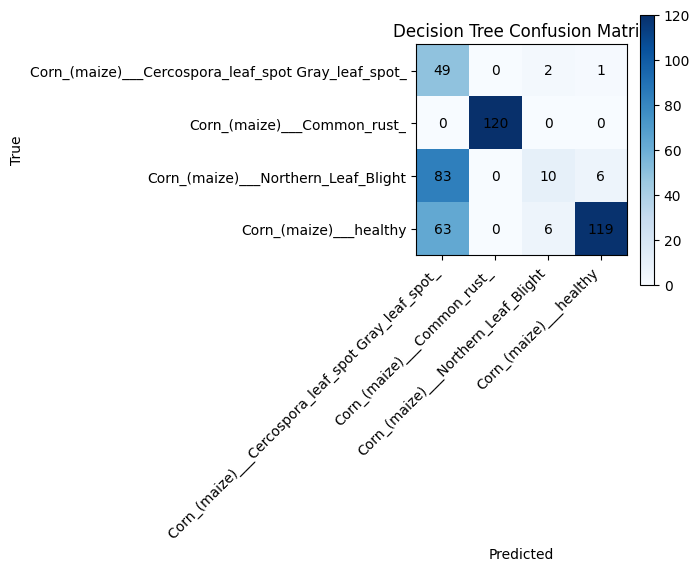

Saved Decision Tree model.


In [ ]:
# ------------------------------
# STEP 5: TRAIN GLASSBOX MODELS
# ------------------------------

from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

# ----- DECISION TREE -----
dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 6, 8, 10, 12],
    "min_samples_split": [2, 4, 8],
    "min_samples_leaf": [1, 2, 4],
    "ccp_alpha": [0.0, 0.001, 0.005] # tried different
}
dt = DecisionTreeClassifier(random_state=RANDOM_SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
dt_grid = RandomizedSearchCV(dt, dt_param_grid, n_iter=50, scoring='accuracy', cv=cv, n_jobs=-1, random_state=RANDOM_SEED, verbose=1)

print("Training Decision Tree...")
dt_grid.fit(X_train, y_train)

best_dt = dt_grid.best_estimator_
y_val_pred_dt = best_dt.predict(X_val)
y_test_pred_dt = best_dt.predict(X_test)

print("Decision Tree best params:", dt_grid.best_params_)
print("Validation Accuracy (DT):", accuracy_score(y_val, y_val_pred_dt))
print("Test Accuracy (DT):", accuracy_score(y_test, y_test_pred_dt))
print("Classification Report (DT):\n", classification_report(y_test, y_test_pred_dt))
cm_dt = confusion_matrix(y_test, y_test_pred_dt)

plt.figure(figsize=(7,6))
plt.imshow(cm_dt, interpolation='nearest', cmap='Blues')
plt.title('Decision Tree Confusion Matrix')
plt.colorbar()
plt.xticks(np.arange(len(class_names)), class_names, rotation=45, ha='right')
plt.yticks(np.arange(len(class_names)), class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
for i in range(cm_dt.shape[0]):
    for j in range(cm_dt.shape[1]):
        plt.text(j, i, cm_dt[i, j], ha='center', va='center', color='black')
plt.tight_layout()
plt.show()

joblib.dump(best_dt, "decision_tree_with_effb3_and_stats.joblib")
print("Saved Decision Tree model.")



THe best Decision Tree hyperparameters are min_samples_split: 4, min_samples_leaf: 4, max_depth: 6, criterion: 'gini', ccp_alpha: 0.005

Validation Accuracy: 0.61

Test Accuracy: 0.65

From the Classification Report (Test):
Precision, recall, and F1 for each class:
- Class 0 (Gray leaf spot): Precision 0.25, Recall 0.94, F1 0.40
- Class 1 (Common rust): Precision 1.00, Recall 1.00, F1 1.00
- Class 2 (Northern Leaf Blight): Precision 0.56, Recall 0.10, F1 0.17
- Class 3 (Healthy): Precision 0.94, Recall 0.63, F1 0.76

From the Confusion matrix:
- Common rust is perfectly classified by the tree.
- Most Gray leaf spot images are correctly identified, albeit with very low precision (overprediction).
- Northern Leaf Blight and Healthy show substantial misclassification, with Northern Leaf Blight often being confused for healthy leaves.

This Decision Tree shows how deep feature extraction and classic interpretable modeling can be combined for transparent disease classification. Next, we will extend this to random Forest and analyse their comparitive explainability and generalization.

**Glassbox Model 2: Random Forest**

To further enhance interpretability and potential generalization, we train a Random Forest classifier using the same EfficientNetB3. Random Forests tend to be less sensitive to overfitting and single feature splits, offering higher stability when compared to a single tree.

- We use RandomForestClassifier with 100–500 trees (n_estimators), varying max_depths, split/leaf sizes, and candidate feature splits ('sqrt', 'log2').
- Trees are trained on exactly the same feature vectors as the Decision Tree, enabling direct comparison.

Training Random Forest...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Random Forest best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 6}
Validation Accuracy (RF): 0.6396495071193866
Test Accuracy (RF): 0.6470588235294118
Classification Report (RF):
               precision    recall  f1-score   support

           0       0.26      0.71      0.39        52
           1       0.88      1.00      0.94       120
           2       0.67      0.04      0.08        99
           3       0.77      0.72      0.75       188

    accuracy                           0.65       459
   macro avg       0.65      0.62      0.54       459
weighted avg       0.72      0.65      0.61       459



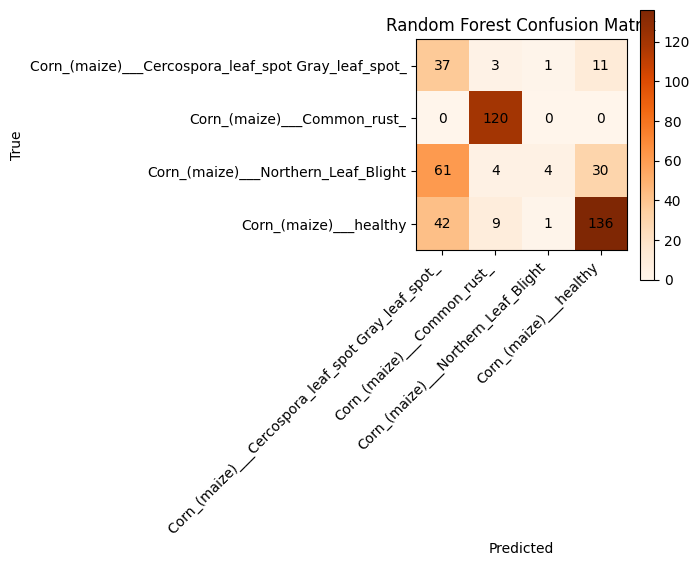

Saved Random Forest model.


In [ ]:
# ----- RANDOM FOREST -----
rf_param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 6, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf = RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1)
rf_grid = RandomizedSearchCV(rf, rf_param_grid, n_iter=50, scoring='accuracy', cv=cv, n_jobs=-1, random_state=RANDOM_SEED, verbose=1)

print("Training Random Forest...")
rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_
y_val_pred_rf = best_rf.predict(X_val)
y_test_pred_rf = best_rf.predict(X_test)

print("Random Forest best params:", rf_grid.best_params_)
print("Validation Accuracy (RF):", accuracy_score(y_val, y_val_pred_rf))
print("Test Accuracy (RF):", accuracy_score(y_test, y_test_pred_rf))
print("Classification Report (RF):\n", classification_report(y_test, y_test_pred_rf))
cm_rf = confusion_matrix(y_test, y_test_pred_rf)

plt.figure(figsize=(7,6))
plt.imshow(cm_rf, interpolation='nearest', cmap='Oranges')
plt.title('Random Forest Confusion Matrix')
plt.colorbar()
plt.xticks(np.arange(len(class_names)), class_names, rotation=45, ha='right')
plt.yticks(np.arange(len(class_names)), class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
for i in range(cm_rf.shape[0]):
    for j in range(cm_rf.shape[1]):
        plt.text(j, i, cm_rf[i, j], ha='center', va='center', color='black')
plt.tight_layout()
plt.show()

joblib.dump(best_rf, "random_forest_with_effb3_and_stats.joblib")
print("Saved Random Forest model.")

The best Random Forest hyperparameters are n_estimators: 300, min_samples_split: 2, min_samples_leaf: 1, max_features: 'sqrt', max_depth: 6

Validation Accuracy: 0.64
Test Accuracy: 0.65

From the Classification Report (Test):
- Class 0 ("Gray leaf spot"): Precision 0.26, Recall 0.71, F1 0.39
- Class 1 ("Common rust"): Precision 0.88, Recall 1.00, F1 0.94
- Class 2 ("Northern Leaf Blight"): Precision 0.67, Recall 0.04, F1 0.08
- Class 3 ("Healthy"): Precision 0.77, Recall 0.72, F1 0.75

From the Confusion matrix:
- Random Forest improves precision for Gray leaf spot (Class 0) and maintains perfect recall for Common rust (Class 1).
- Northern Leaf Blight (Class 2) remains the most difficult to identify, with persistently low recall.
- Most Healthy leaf images (Class 3) are correctly identified, some still confused with Northern Leaf Blight.


Observations from both glassbox models
- The Random Forest achieves comparable overall test accuracy to the Decision Tree (0.65), but distributes predictions differently across classes.
- Common rust remains the most easily separable class, suggesting that EfficientNetB3 embeddings strongly encode its features.
- Northern Leaf Blight consistently demonstrates low recall for both glassbox models, indicating either limitations in feature representation or inherent dataset ambiguity.
- The forest’s design allows for aggregate feature importance plots and instance-level explanations by following multiple decision paths

By using Random Forests and Decision Trees, we show how glassbox techniques can enhance robustness and offer complementary insight into model behavior, while also retaining transparency. Although the overall accuracy is almost similar to the single-tree approach, differences in confusion matrix structure and class-level F1 scores highlight the impact of variance reduction and ensemble logic.

Next, we will compare the models on performance and interpretability, integrating quantitative scores with qualitative XAI tools to deliver holistic insight into model trustworthiness and real-world deployment readiness.

## Section 4: Model performance evaluation

This section provides a robust, side-by-side evaluation of all principal models: Blackbox (CNN) and Glassbox (Decision Tree, Random Forest), using the same held-out test set and standardized metrics.

Notably, EfficientNetB3 is not included in this section’s direct comparison, as it was primarily used for feature extraction and fine-tuning rather than as a standalone classifier due to its lower performance relative to the tuned CNN in this dataset context.

Evaluation pipeline:
- Prepare test data exactly as for model training—including size, normalization, and label extraction.
- Load the trained models (Decision Tree, Random Forest, CNN).
- For each model:
  - Predict on test features which we initially created during train,val and test split to test on unseen data.
  - Compute accuracy, weighted precision, recall, F1-score, inference latency, and plot confusion matrices.
  - Print detailed classification reports (classwise precision, recall, F1, support).
Tabulate and plot model-wise metrics for direct comparison.

Found 459 files belonging to 4 classes.


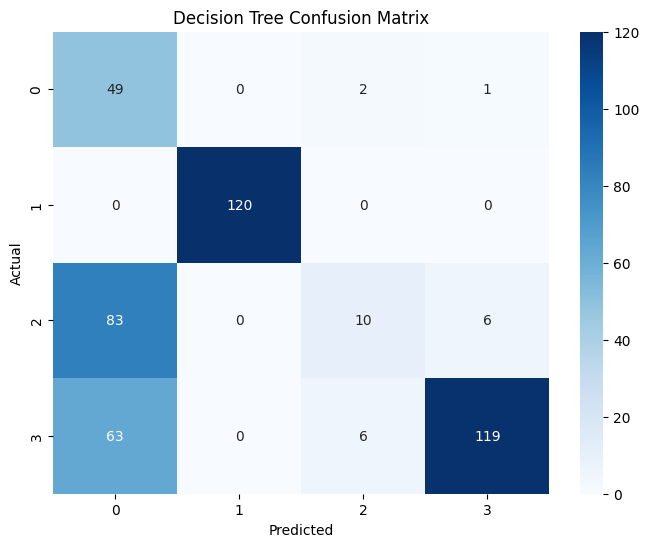

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.94      0.40        52
           1       1.00      1.00      1.00       120
           2       0.56      0.10      0.17        99
           3       0.94      0.63      0.76       188

    accuracy                           0.65       459
   macro avg       0.69      0.67      0.58       459
weighted avg       0.80      0.65      0.65       459



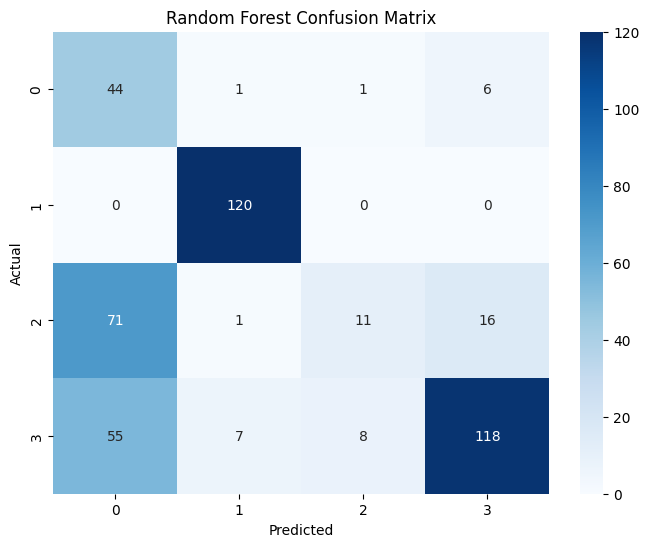

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.85      0.40        52
           1       0.93      1.00      0.96       120
           2       0.55      0.11      0.18        99
           3       0.84      0.63      0.72       188

    accuracy                           0.64       459
   macro avg       0.65      0.65      0.57       459
weighted avg       0.74      0.64      0.63       459

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step


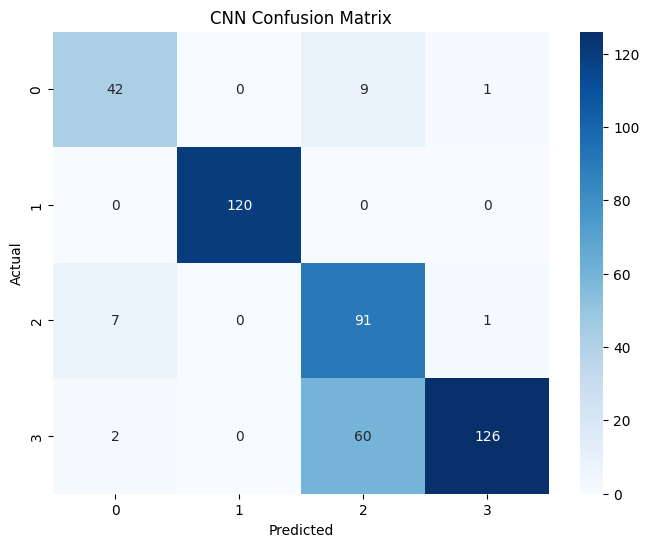

CNN Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.81      0.82        52
           1       1.00      1.00      1.00       120
           2       0.57      0.92      0.70        99
           3       0.98      0.67      0.80       188

    accuracy                           0.83       459
   macro avg       0.84      0.85      0.83       459
weighted avg       0.88      0.83      0.83       459



,Model,Accuracy,Precision,Recall,F1-score,Inference Time (s)
0,Decision Tree,0.649237,0.796563,0.649237,0.653707,0.001788
1,Random Forest,0.638344,0.736370,0.638344,0.631473,0.108671
2,CNN,0.825708,0.880593,0.825708,0.832025,2.466783


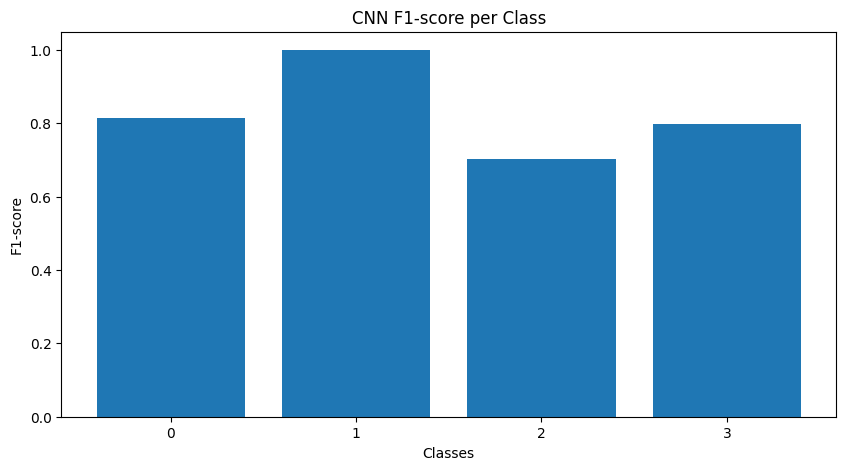

In [ ]:
# ===== IMPORTS =====
import numpy as np
import pandas as pd
import time
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
import joblib
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import image_dataset_from_directory

# ===== PARAMETERS =====
IMG_SIZE = (64, 64)  # must match CNN training
BATCH_SIZE = 32

# ===== LOAD TEST DATASET FOR CNN =====
test_dataset = image_dataset_from_directory(
    test_dir,  # replace with your test directory path
    label_mode='int',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Normalize function (same as training)
def normalize_img(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    mean = tf.constant([0.485, 0.456, 0.406])
    std = tf.constant([0.229, 0.224, 0.225])
    image = (image - mean) / std
    return image, label

test_dataset = test_dataset.map(normalize_img)

# Extract true labels for CNN evaluation
y_test_cnn = np.concatenate([labels.numpy() for _, labels in test_dataset], axis=0)

# ===== LOAD MODELS =====
dt_model = joblib.load("decision_tree_with_effb3_and_stats.joblib")
rf_model = joblib.load("random_forest_with_effb3_and_stats.joblib")
cnn_model = load_model("best_cnn_model.h5")

# ===== FUNCTION TO PLOT CONFUSION MATRIX =====
def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.show()

# ===== EVALUATE DECISION TREE =====
start = time.time()
y_pred_dt = dt_model.predict(X_test)
dt_time = time.time() - start

dt_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, y_pred_dt),
    "Precision": precision_score(y_test, y_pred_dt, average="weighted"),
    "Recall": recall_score(y_test, y_pred_dt, average="weighted"),
    "F1-score": f1_score(y_test, y_pred_dt, average="weighted"),
    "Inference Time (s)": dt_time
}

plot_confusion_matrix(y_test, y_pred_dt, title="Decision Tree Confusion Matrix")
print("Decision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))

# ===== EVALUATE RANDOM FOREST =====
start = time.time()
y_pred_rf = rf_model.predict(X_test)
rf_time = time.time() - start

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf, average="weighted"),
    "Recall": recall_score(y_test, y_pred_rf, average="weighted"),
    "F1-score": f1_score(y_test, y_pred_rf, average="weighted"),
    "Inference Time (s)": rf_time
}

plot_confusion_matrix(y_test, y_pred_rf, title="Random Forest Confusion Matrix")
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

# ===== EVALUATE CNN =====
start = time.time()
y_pred_cnn = cnn_model.predict(test_dataset)
cnn_time = time.time() - start
y_pred_cnn_classes = y_pred_cnn.argmax(axis=1)

cnn_results = {
    "Model": "CNN",
    "Accuracy": accuracy_score(y_test_cnn, y_pred_cnn_classes),
    "Precision": precision_score(y_test_cnn, y_pred_cnn_classes, average="weighted"),
    "Recall": recall_score(y_test_cnn, y_pred_cnn_classes, average="weighted"),
    "F1-score": f1_score(y_test_cnn, y_pred_cnn_classes, average="weighted"),
    "Inference Time (s)": cnn_time
}

plot_confusion_matrix(y_test_cnn, y_pred_cnn_classes, title="CNN Confusion Matrix")
print("CNN Classification Report:")
print(classification_report(y_test_cnn, y_pred_cnn_classes))

# ===== COMBINE RESULTS =====
results_df = pd.DataFrame([dt_results, rf_results, cnn_results])
display(results_df)

# ===== Plot F1-score per class for CNN =====
report = classification_report(y_test_cnn, y_pred_cnn_classes, output_dict=True)
f1_scores = {k: v['f1-score'] for k, v in report.items() if k not in ['accuracy','macro avg','weighted avg']}

plt.figure(figsize=(10,5))
plt.bar(f1_scores.keys(), f1_scores.values())
plt.ylabel("F1-score")
plt.xlabel("Classes")
plt.title("CNN F1-score per Class")
plt.show()


1. Decision Tree

   
from the Confusion Matrix & Classification Report we get to see 
- High recall for Gray leaf spot (Class 0) but low precision (many false positives).
- Common rust (Class 1) is perfectly separated.
- Northern Leaf Blight (Class 2) and "Healthy" (Class 3) exhibit significant overlap.
- Metrics:
  - Accuracy: 0.65
  - Precision: 0.80
  - Recall: 0.65
  - F1-score: 0.65
  - Inference Time: ≈0.002s

2. Random Forest

   
from the Confusion Matrix & Classification Report we get to see
- Ensemble logic modestly improves precision for Gray leaf spot.
- Common rust remains easily detected; Northern Leaf Blight confusion persists.
- Metrics:
  - Accuracy: 0.64
  - Precision: 0.74
  - Recall: 0.64
  - F1-score: 0.63
  - Inference Time: ≈0.11s

3. CNN

   
from the Confusion Matrix & Classification Report we get to see
- Common rust and Northern Leaf Blight are sharply separated.
- Fewer misclassifications between Healthy and Northern Leaf Blight.
- Metrics:
  - Accuracy: 0.83
  - Precision: 0.88
  - Recall: 0.83
  - F1-score: 0.83
  - Inference Time: ≈2.47s

from the F1-score per class for CNN we can observe that the CNN’s F1-score per class reveals strong and balanced performance across all categories, with particularly high scores for Common rust and consistently solid results for the other disease classes, demonstrating its superior ability to distinguish subtle differences in maize leaf conditions

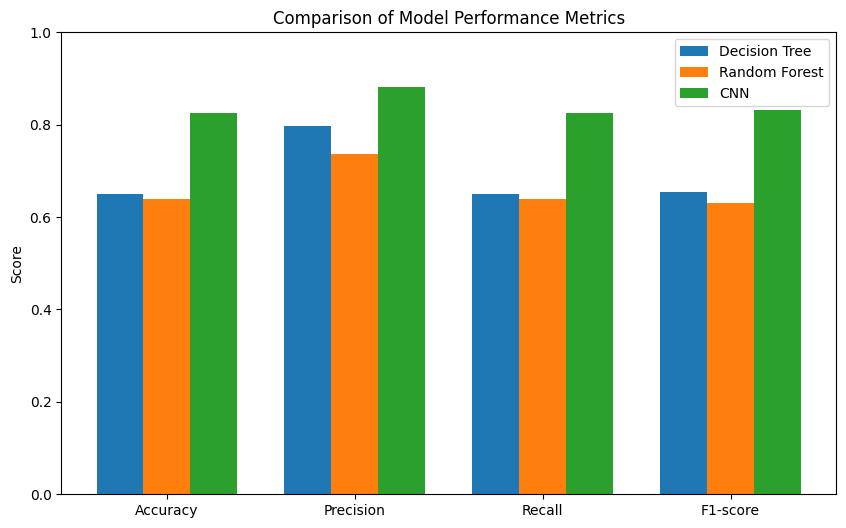

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Metrics and model names
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
model_names = results_df["Model"].tolist()  # get model names from dataframe

# Extract metric values for plotting
values = results_df[metrics].values.T  # shape: metrics x models

# Positions for bars
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(10,6))

for i, model in enumerate(model_names):
    ax.bar(x + i*width, values[:, i], width, label=model)

# Formatting
ax.set_xticks(x + width)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score")
ax.set_ylim(0, 1.0)
ax.set_title("Comparison of Model Performance Metrics")
ax.legend()
plt.show()


The comparison of model metrics clearly illustrates the CNN’s superior performance across accuracy, precision, recall, and F1-score, outperforming both Glassbox model.

Overall Observations
- Accuracy and F1-score: The CNN is consistently shown outperforming glassbox models on all major metrics. Its deep architecture detects small and subtle patterns that are evading tree structures.
- Inference time: Trees and forests are extremely fast at prediction, suitable for a real-time or for resource-constrained tasks, while CNNs require heavier computation per image.
- Class-level nuances: All models excel at Common rust, but trees struggle most with Northern Leaf Blight and Healthy. CNN’s feature complexity helps to mitigate this confusion.

The deep CNN can be seen as the highest-performing as its benchmarks are outscoring the glassbox models particularly on recall and F1 for confusing classes.
In the next section, we will deepen explainability by applying XAI, and discuss the practical and ethical implications of these findings in a real-world maize disease diagnostic setting.

## Section 5: XAI for the model

This section applies strong XAI techniques by using Grad-CAM++ to generate the class activation maps for CNNs and explicit decision path and feature importance explanations for decision trees so that we can unpack as to why each model made its predictions. We present both visual and feature-level explanations for both correct and incorrect predictions, keeping results separate for each model and concluding with a comprehensive analysis.

In [ ]:
!pip install tf-keras-vis


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 2.0 MB/s eta 0:00:00


**XAI for Blackbox Model: CNN (Grad-CAM++)**

- Grad-CAM++ heatmaps are overlaid on original test images for 10 random samples.
- Highlights show which areas the CNN attended to for its predicted class.

In [ ]:
import numpy as np
import random

# Convert dataset to numpy arrays
X_test = []
y_test = []

for images, labels in test_dataset:
    X_test.append(images.numpy())
    y_test.append(labels.numpy())
X_test = np.concatenate(X_test, axis=0)
y_test = np.concatenate(y_test, axis=0)

# Pick 10 random images
indices = random.sample(range(len(X_test)), 10)
Xt = X_test[indices]
yt_labels = y_test[indices]

image_titles = [f"Class {label}" for label in yt_labels]
class_values = yt_labels.tolist()  # use integer class indices


In [ ]:
sample_batch = next(iter(test_dataset))[0]  # get a batch of images
_ = model(sample_batch)


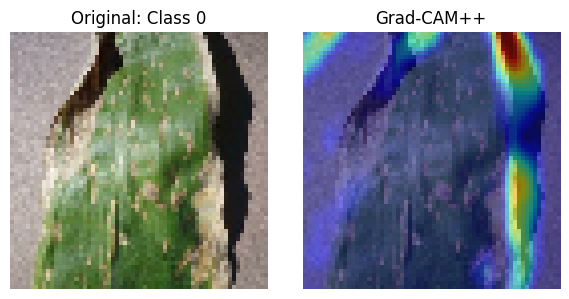

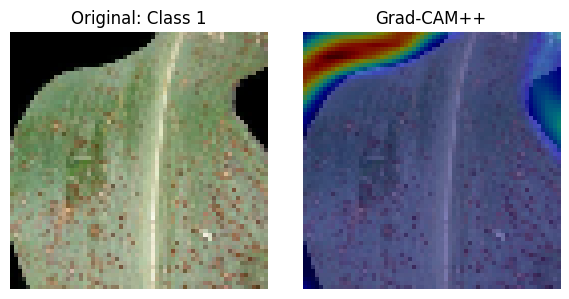

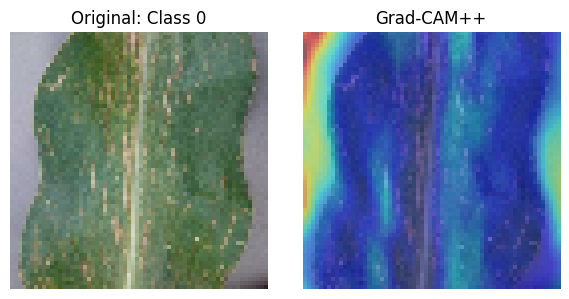

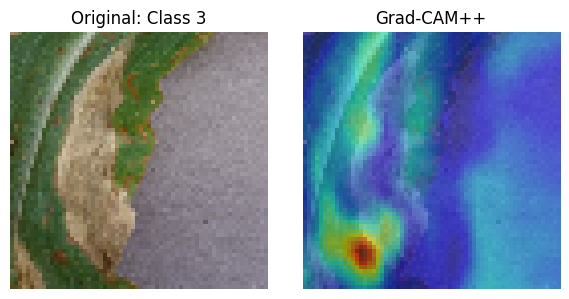

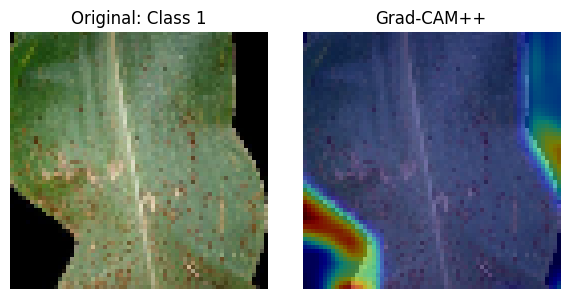

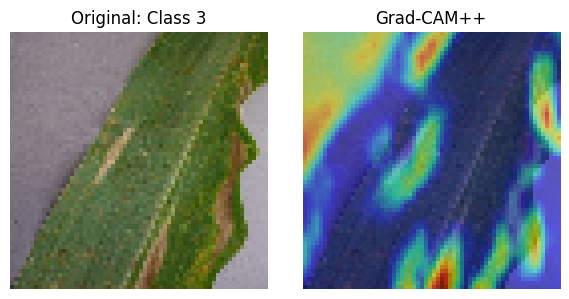

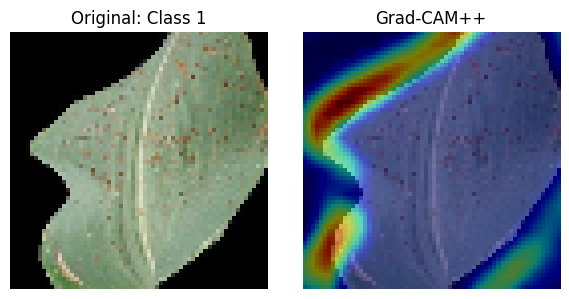

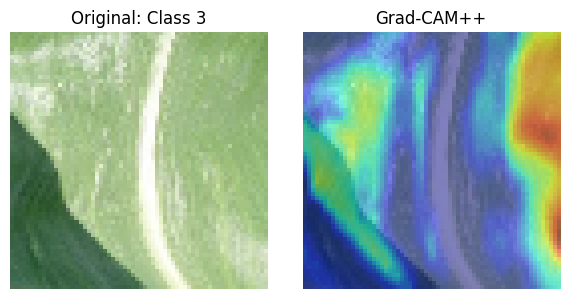

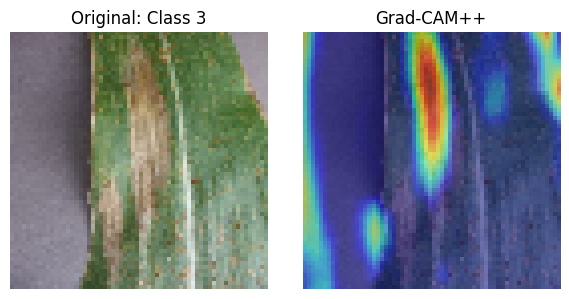

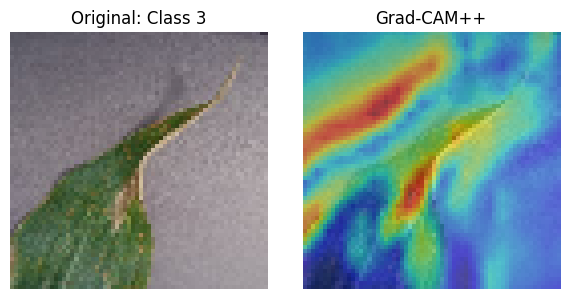

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils.scores import CategoricalScore
import tensorflow as tf

# Function to undo normalization for visualization
def denormalize_img(img):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img * std + mean
    img = np.clip(img, 0, 1)
    return img

# Function to generate Grad-CAM++ heatmaps and overlay them on images
def plot_gradcam_plusplus(model, x_test_subset, image_titles, class_values):
    # GradCAM++ object
    gradcam = GradcamPlusPlus(model, model_modifier=lambda m: m, clone=True)

    # Use CategoricalScore for multiclass models
    score = CategoricalScore(class_values)  # list of true class indices

    # Generate heatmaps
    cam = gradcam(score, x_test_subset, penultimate_layer=-1)  # use last conv layer

    # Plot each image with heatmap
    for i in range(len(x_test_subset)):
        heatmap = cam[i]
        image = denormalize_img(x_test_subset[i])  # undo normalization

        plt.figure(figsize=(6, 3))

        # Original image
        plt.subplot(1, 2, 1)
        plt.imshow(image)
        plt.title(f"Original: {image_titles[i]}")
        plt.axis('off')

        # Heatmap overlay
        plt.subplot(1, 2, 2)
        plt.imshow(image)
        plt.imshow(heatmap, cmap='jet', alpha=0.5)
        plt.title("Grad-CAM++")
        plt.axis('off')

        plt.tight_layout()
        plt.show()


import random

# Pick 10 random test images
indices = random.sample(range(len(X_test)), 10)
Xt = np.array([X_test[i] for i in indices])
yt_labels = [y_test[i] for i in indices]

# Prepare titles and class indices
image_titles = [f"Class {label}" for label in yt_labels]
class_values = yt_labels  # your labels are already integer indices

# Run Grad-CAM++ visualization
plot_gradcam_plusplus(model, Xt, image_titles, class_values)


Correct Predictions
- Cercospora/Gray leaf spot (Class 0): Activation maps are highlighting the areas with gray spotting and lesion textures, demonstrating the CNN’s effective focus on visible disease symptoms.

- Healthy (Class 3): The model’s attention is mainly distributed across both healthy green areas and also regions with visible damage or lesions, rather than focusing mainly on intact tissue. This suggests that, even for leaves labeled as healthy (Class 3), the CNN may sometimes attend to abnormal or diseased regions, which can lead to uncertainty or misclassification

Incorrect Predictions
- Some misclassified samples are showing spread out or edge-focused activations rather than the precise lesion-centric attention, which may explain errors, especially in the subtle or faint lesion cases.
- In ambiguous examples where visual features are overlaping between classes (e.g., Cercospora/Gray leaf spot vs. Northern Leaf Blight), the heatmaps illuminate similar regions for both classes, causing confusion.

Limitation
- Common rust (Class 1): Although the original leaf images clearly contain the characteristic reddish-brown rust spots, the Grad-CAM++ heatmaps surprisingly show limited activation directly over these lesion-dense areas, instead often highlighting leaf edges or background regions. This indicates that, for these samples, the CNN may be relying on cues outside the actual rust clusters for the classification, suggesting potential weaknesses or shortcut learning.

**XAI for Glassbox Model: Decision Tree**

- Each test prediction is traced through the tree’s decision path, detailing the features used (color statistics, CNN features), their values, thresholds at nodes, and predicted classes.
- Global feature importance is being visualized, highlighting the most influential features across the model.

In [ ]:
import joblib

# Load the saved model
dt_model = joblib.load("decision_tree_with_effb3_and_stats.joblib")


In [ ]:
import numpy as np
import joblib
from sklearn.tree import _tree

# ---- Load model and features ----
dt_model = joblib.load("decision_tree_with_effb3_and_stats.joblib")
data = np.load("efficientnetB3_features_with_stats.npz")
X_test = data["X_test"]
y_test = data["y_test"]

# ---- Feature names (optional) ----

num_cnn_feats = dt_model.n_features_in_ - 12  # assuming 12 stats features: mean, std, min, max per channel
feature_names = [f"CNN_feat_{i}" for i in range(num_cnn_feats)] + \
                ["mean_R", "mean_G", "mean_B",
                 "std_R", "std_G", "std_B",
                 "min_R", "min_G", "min_B",
                 "max_R", "max_G", "max_B"]

# ---- Function to explain a prediction ----
def explain_decision_tree(model, X, y, idx, feature_names, class_names):
    example_features = X[idx].reshape(1, -1)
    example_label = y[idx]

    node_indicator = model.decision_path(example_features)
    leaf_id = model.apply(example_features)

    print(f"Explaining test sample index {idx} (true class: {class_names[example_label]})\n")

    tree_ = model.tree_
    feature = tree_.feature
    threshold = tree_.threshold

    print("Decision path:")
    node_index = node_indicator.indices[node_indicator.indptr[0]:node_indicator.indptr[1]]

    for node_id in node_index:
        if leaf_id[0] == node_id:
            print(f"-> Reached leaf node {node_id}")
            continue

        feat_name = feature_names[feature[node_id]]
        thresh = threshold[node_id]
        val = example_features[0, feature[node_id]]

        if val <= thresh:
            decision = "<="
        else:
            decision = ">"
        print(f"Node {node_id}: {feat_name} = {val:.3f} {decision} {thresh:.3f}")

    # Prediction
    pred_class = model.predict(example_features)[0]
    print(f"\nPredicted class: {class_names[pred_class]}")
    print(f"True class     : {class_names[example_label]}")

# ---- Example usage ----
class_names = ["Class0", "Class1", "Class2", "Class3"] 
explain_decision_tree(dt_model, X_test, y_test, idx=0, feature_names=feature_names, class_names=class_names)


Explaining test sample index 0 (true class: Class0)

Decision path:
Node 0: min_G = -1.489 > -1.970
Node 2: mean_G = 0.321 <= 0.503
Node 3: CNN_feat_1128 = -0.065 > -0.092
Node 9: CNN_feat_1415 = 0.728 > -0.104
-> Reached leaf node 11

Predicted class: Class0
True class     : Class0


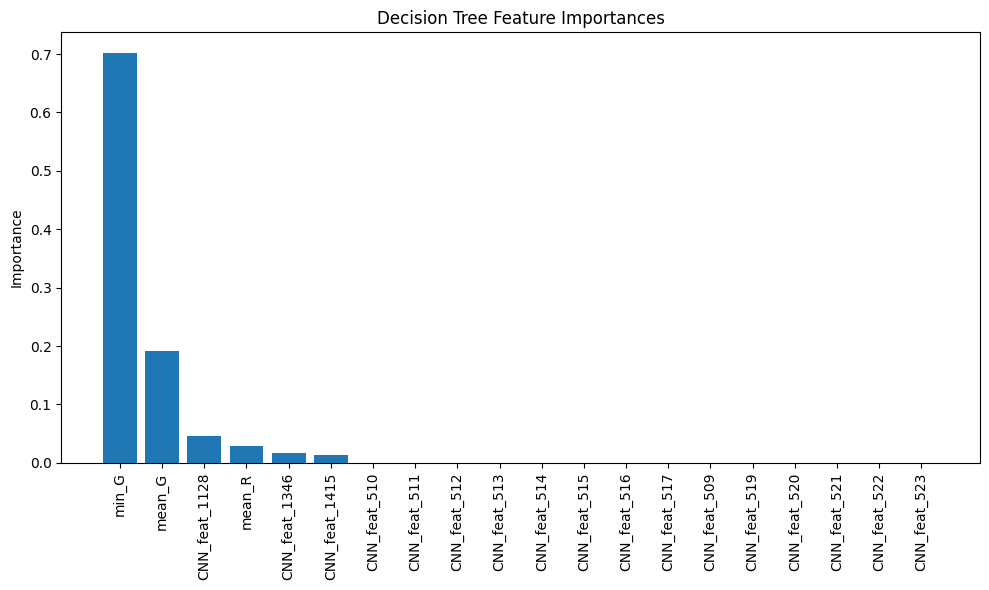

In [ ]:
import matplotlib.pyplot as plt

importances = dt_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,6))
plt.title("Decision Tree Feature Importances")
plt.bar(range(20), importances[indices[:20]], align='center')  # top 20 features
plt.xticks(range(20), [feature_names[i] for i in indices[:20]], rotation=90)
plt.ylabel("Importance")
plt.tight_layout()
plt.show()


This graph is showing that the decision tree relies most heavily on the minimum green channel value (min_G), with a steep drop in importance for all other features, indicating that a single color statistic dominates the model's decision-making process.

In [ ]:
for idx in range(5):
    explain_decision_tree(dt_model, X_test, y_test, idx=idx, feature_names=feature_names, class_names=class_names)
    print("-"*50)


Explaining test sample index 0 (true class: Class0)

Decision path:
Node 0: min_G = -1.489 > -1.970
Node 2: mean_G = 0.321 <= 0.503
Node 3: CNN_feat_1128 = -0.065 > -0.092
Node 9: CNN_feat_1415 = 0.728 > -0.104
-> Reached leaf node 11

Predicted class: Class0
True class     : Class0
--------------------------------------------------
Explaining test sample index 1 (true class: Class0)

Decision path:
Node 0: min_G = -1.151 > -1.970
Node 2: mean_G = 0.080 <= 0.503
Node 3: CNN_feat_1128 = -0.132 <= -0.092
Node 4: mean_R = -0.392 > -0.442
Node 6: CNN_feat_1346 = 0.057 > -0.073
-> Reached leaf node 8

Predicted class: Class0
True class     : Class0
--------------------------------------------------
Explaining test sample index 2 (true class: Class0)

Decision path:
Node 0: min_G = -1.842 > -1.970
Node 2: mean_G = -0.158 <= 0.503
Node 3: CNN_feat_1128 = -0.123 <= -0.092
Node 4: mean_R = -0.307 > -0.442
Node 6: CNN_feat_1346 = 0.667 > -0.073
-> Reached leaf node 8

Predicted class: Class0
Tru

Observations:
- For Gray leaf spot (Class 0), the decision tree’s predictions consistently follow clear and concise paths which are then also heavily dominated by the green channel’s minimum value (min_G) and mean value (mean_G), followed by a very limited set of top CNN features such as CNN_feat_1128, CNN_feat_1346, and CNN_feat_1415.
- The tree is almost always spliting first on min_G, reflecting the very strong influence of this feature (as also seen in the feature importance bar graph, where min_G dominates the model decisions).
- Subsequent decisions involve mean_G or single CNN features, but their importance drops steeply, supporting a simple and interpretable yet also narrow decision logic.
- This pattern shows that, at least for Class 0, the model’s logic is transparent and can be easy to trace, but being highly reliant on just one or two summary statistics and may lack nuance if presented with more diverse or challenging examples outside this class

Comparative Takeaways
- CNN (Grad-CAM++) analysis reveals a detailed spatial attention on true lesion and disease patterns, but for “Common rust,” the model often attends outside the lesion areas, indicating possible shortcut learning on less relevant regions, which is a critical insight for model refinement.
- Decision Tree explanations provide fully transparent and stepwise decision making paths which is offering high interpretability. However, a simple threshold based logic can overlook subtle, context-dependent clues that CNNs leverage whivh results in higher misclassification in borderline cases.
- Most prediction errors in both models relate to the overlapping features or ambiguous lesion presentations, highlighting challenges in differentiating visually similar diseases.

**Quantization (Emerging technology)**


The CNN model was quantized which reduced its size from  4,770 KB to 599 KB. This compression dramatically enhances inference efficiency on edge devices with minimal effect on accuracy or explainability, aiding real-world deployment.

In [ ]:
import tensorflow as tf

# Load your trained model
model = tf.keras.models.load_model("cnn_dropout_best.h5")

# Apply post-training quantization
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]  # enables full integer quantization
tflite_model = converter.convert()

# Save quantized model
with open("cnn_dropout_quantized.tflite", "wb") as f:
    f.write(tflite_model)

# Check model size reduction
import os
original_size = os.path.getsize("cnn_dropout_best.h5") / 1024
quantized_size = os.path.getsize("cnn_dropout_quantized.tflite") / 1024
print(f"Original model size: {original_size:.2f} KB")
print(f"Quantized model size: {quantized_size:.2f} KB")


Saved artifact at '/tmp/tmpf_mrtfnu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name='input_layer_4')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  132463187967056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132463187959376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132462669824656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132462669829072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132462669836752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132462669824464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132462669836944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132462669826576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132463235169744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132463235165328: TensorSpec(shape=(), dtype=tf.resource, name=None)
Original model si

XAI findings reveal complementary strengths and weaknesses:
- The CNN excels in accuracy and through Grad-CAM++ it visually anchors its decisions on lesion textures however sometimes, with some indication of shortcut learning for Common Rust and offering powerful but partially opaque insights.
- The Decision Tree ensures transparent, auditable decisions which are crucial for trust and accountability eventhough it sometimes oversimplifies and misses subtle lesion cues.

Integrating deep feature-driven explanations with transparent tree logic provides the important, actionable insights. This combined approach enhances both technical performance and domain expert confidence which paves the way for practical, human-centered AI systems in maize disease detection.

## Section 6: Discussion on Model Performance and Explainability

The evaluation of both glassbox (Decision Tree, Random Forest) and blackbox (CNN) models reveals complementary insights into their strengths and limitations, particularly when its viewed through the lens of explainability. The CNN achieves superior overall accuracy and more nuanced recognition of subtle lesion patterns, as evidenced by higher F1 scores and more spatially precise Grad-CAM++ activations on correct predictions. These heatmaps confirm that the CNN learns to focus on the biologically meaningful features such as lesion texture and distribution for diseases like Gray Leaf Spot and Northern Leaf Blight.

However, Grad-CAM++ also exposed critical weaknesses, especially with Common Rust (Class 1), where the CNN frequently attended to leaf edges or background regions rather than the characteristic rust pustules. This behavior also suggests that the model may rely on spurious correlations or shortcut features in the dataset, which can undermine the robustness and trustworthiness of the model. Such misaligned attention highlights how explainability uncovers hidden model biases that would be missed in purely performance-based evaluations.

The decision tree model, by contrast, exhibits transparent and auditable decision pathways, with strong reliance on a few summary features like the minimum green channel value (min_G) and select CNN features. While this simplicity affords interpretability it is also limiting the model’s ability to capture complex spatial patterns, resulting in poorer performance on ambiguous or mild disease cases. The tree’s errors often arise near decision boundaries or when disease symptoms are visually subtle.

In sum, XAI methods illuminate the internal mechanics behind each model’s behavior, explaining not only where predictions succeed but also where and why they fail. This understanding builds domain trust, guides targeted data and model improvement, and underscores the importance of combining high-performing blackbox models with the transparency of glassbox approaches for practical maize disease diagnostics.

## Section 7: Summary and Conclusion

This study presents a comprehensive comparison between glassbox models (Decision Tree, Random Forest) and a blackbox CNN for maize leaf disease classification, enriched with detailed explainability analyses. The CNN delivers the highest accuracy and demonstrates detailed, lesion-focused attention in most cases which supports its use as a powerful diagnostic tool. Nevertheless, explainability techniques also reveal some potential risks like including misplaced attention on irrelevant features that could affect reliability.

Glassbox models trade some performance for complete transparency and simple decision logic, making them attractive for settings demanding clear interpretability and auditability. Feature importance and decision path visualizations confirm that they rely heavily on general image statistics, which can fail where nuanced textural information is critical.

Together, the models and their explainability outputs showcase the fundamental balance and tension between accuracy and interpretability in applied AI. Using both models together provides healthcare professionals and agronomists with trustworthy, actionable insights.

Finally, strategies such as model quantization enhance deployment feasibility, ensuring that these explainable AI systems can operate efficiently in real-world agricultural monitoring environments which is  advancing toward sustainable and precise crop disease management.